In [1]:
#Compare flux density values of eruptions, not just the slope 

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import ScalarFormatter
from scipy.stats import linregress
from scipy.optimize import curve_fit
import math
import matplotlib.ticker as ptk

from astropy.modeling.powerlaws import BrokenPowerLaw1D, SmoothlyBrokenPowerLaw1D, PowerLaw1D 
from astropy.modeling import fitting, models

Notes on the data:

1985: 

2006:
Kantharia: https://arxiv.org/pdf/0708.1216
(The uncertainty in the flux scale is ∼ 15% and the errors on the flux densities listed in Table 1 reflect this uncertainty)

Eyres+2009: https://articles.adsabs.harvard.edu/pdf/2009MNRAS.395.1533E
(did not see anything about calibration errors added) 

2021: 
Ruiter+23: https://arxiv.org/pdf/2301.10552 
(errors consist of a fit error fit, determined by PySE, and a 10% systematic flux error) 

Nayana+24: https://arxiv.org/pdf/2401.05643 (All freq. under 2 GHz)
"In addition to the errors on flux densities from task JMFIT, we add (in quadrature) a 10% error in bands-3, 4, and 5 and a 15% error in band-2 to account for the calibration uncertainties."


Kirill?: VLA data not published (no added flux calibration to errors) 

## Load data files and sort

In [2]:
#load in data files 

rs_2021a = pd.read_csv('rs_oph21.csv', sep='\s+', header = 0)
rs_2021b = pd.read_csv('RSOPH_uGMRT', sep='\s+', header = 0)                 #Nayana
rs_2021c = pd.read_csv('RSOPH_Meerkat+21.txt', sep='\s+', header = 0)        #de Ruiter

rs_2006a = pd.read_csv('RSOph_06.txt', sep='\s+', header = 0)
rs_2006b = pd.read_csv('Rs_Oph_2006.txt', sep='\s+', header = 0) #Kantharia+07
rs_2006c = pd.read_csv('rs_oph_06_eyres.txt', sep='\s+', header = 0) #Eyres


rs_1985 = pd.read_csv('rs_1985.csv', header = 0, engine='python')



In [3]:
#1985 Data 

#Sort data into freq, date, flux and error 
#Day of outburst: 1985 January 26, JD 2,446,091
#Date JD - 2,446,000

jd_85 = rs_1985['JD']
S1_85 = rs_1985['1.49GHz'] #For 1.49 GHz
er1_85 = rs_1985['Er1'] 

S2_85 = rs_1985['4.85GHz'] #For 4.85 GHz
er2_85 = rs_1985['Er2'] 

S3_85 = rs_1985['14.94GHz'] #For 14.49 GHz
er3_85 = rs_1985['Er3'] 

S4_85 = rs_1985['22.46GHz'] #For 22.46 GHz
er4_85 = rs_1985['Er4'] 

In [4]:
#2006 Data 
a_06_day = rs_2006a['Day']
a_06_F = rs_2006a['F']
a_06_S = rs_2006a['S']
a_06_E = rs_2006a['E']

b_06_day = rs_2006b['#Day']
b_06_F = rs_2006b['v(Ghz)']
b_06_S = rs_2006b['S(mJy)']
b_06_E = rs_2006b['Er']

c_06_day = rs_2006c['Day']
c_06_F = rs_2006c['Freq']
c_06_S = rs_2006c['Flux']
c_06_E = rs_2006c['Er']


In [5]:
#2021 Data 
mjd_21 = rs_2021a['MJD']
a_21_F = rs_2021a['Frequency(GHz)']
a_21_S = rs_2021a['Fluxdensity(mJy)']
a_21_E = rs_2021a['error(mJy)']

#b units: (day) (GHz) (mJy)
b_21_day = rs_2021b['Day']
b_21_F = rs_2021b['Frequency']
b_21_S = rs_2021b['Fluxdensity']
b_21_E = rs_2021b['E']


#c units: (UTC) (MJD) (d) (MHz) (min) (mJy)
c_21_day = rs_2021c['day']
c_21_F = rs_2021c['frequency'] #in MHz not GHz
c_21_S = rs_2021c['S']
c_21_E = rs_2021c['E']


## Undo Calibration Errors From Other Papers

In [6]:
#For each error we need to remove the 10 and 15% (37-40) error and then add 5% error 
#Here is our test case day 25.03 flux density + error:  85.10 	± 	8.60 (this one has 10% error added) 

def new_error(E,S):
    e_10 = []
    e_15 = []

    #To undo 10% error:
    for i in range(0,37):
        e_10.append(np.sqrt(np.abs(E[i]**2 - (S[i]*0.10)**2)))
        #To undo 15% error:
    for i in range(37,41):
        e_15.append(np.sqrt(np.abs(E[i]**2 - (S[i]*0.15)**2)))
        
    return(e_10, e_15)

In [7]:
def deRuiter_err(E,S):
    e=[]
    for i in range(len(S)):
        e.append(np.sqrt(np.abs(E[i]**2 - (S[i]*0.10)**2)))

    return(e)

In [8]:
def Kanth_err(E,S):
    e=[]
    for i in range(len(S)):
        e.append(np.sqrt(np.abs(E[i]**2 - (S[i]*0.15)**2)))

    return(e)

In [9]:
#Plug these in to sorting code and error in quadrature 

#2021_b
b_E_10 = np.array(new_error(b_21_E, b_21_S)[0])
b_E_15 = np.array(new_error(b_21_E, b_21_S)[1])


#This is for undoing the 10% errors in the deRuiter paper 

c_e_10 = np.array(deRuiter_err(c_21_E, c_21_S))


#This is for undoing the 15% error in the Kantharia paper
#ONE ISSUE HERE IS THAT THE NON DETECTIONS ARE LISTED AS <FLUX VALUE RESULTING IN NANS
b06_e_15 = np.array(Kanth_err(b_06_E, b_06_S))

## Converting all dates to days since discovery 

In [10]:
#Going from JD to days since eruption for the 1985 eruption 

def JD_to_real(d):
    r_jd = []
    
    for i in range(0,len(d)):
        real_jd = d[i] + 2446000
        r_jd.append(real_jd)
        
    return(r_jd)

cal_date_85 = JD_to_real(jd_85)

#Change real JD to days since the initial outburst on Jan. 26 

def days_since(day):
    day_since = []
    for i in range(0,len(day)):
        sub = day[i] - 2446091
        day_since.append(sub)
        
    return(day_since)

day_85 = days_since(cal_date_85)

In [11]:
#Going from MJD to days since eruption for the 2021 eruption 
#Discovered: August 8, 2021: MJD = 59434


def MJD_to_date(MJD, first):
    days = []
    for i in range(len(MJD)):
        days.append(float(MJD[i]) - first)
    return(days)

a_21_day = np.array(MJD_to_date(mjd_21,59434))

## Check for non detections and sort by frequency

In [12]:
def non_det(f,e,d):
    n_f = []
    n_e = []
    n_d = []
    
    d_f = []
    d_e = []
    d_d = []
    
    for i in range(0,len(f)):
        if f[i] < 3.0 * e[i]:
            n_f.append(f[i] + 3*e[i])
            n_d.append(d[i])
            n_e.append(e[i])
            
        else: 
            d_f.append(f[i])
            d_e.append(e[i])
            d_d.append(d[i])
            
    return(n_f, n_e, n_d, d_f, d_e, d_d)

#1985 
det_nondet_85_1 = non_det(S1_85, er1_85, day_85)
det_nondet_85_2 = non_det(S2_85, er2_85, day_85)
det_nondet_85_3 = non_det(S3_85, er3_85, day_85)
det_nondet_85_4 = non_det(S4_85, er4_85, day_85)



In [13]:
#Freq 1.49 GHz
Det_S1_85 = det_nondet_85_1[3]
Det_err1_85 = det_nondet_85_1[4]
Det_day1_85 = det_nondet_85_1[5]

#Freq 4.85 GHz
Det_S2_85 = det_nondet_85_2[3]
Det_err2_85 = det_nondet_85_2[4]
Det_day2_85 = det_nondet_85_2[5]

#Freq 14.94 GHz
Det_S3_85 = det_nondet_85_3[3]
Det_err3_85 = det_nondet_85_3[4]
Det_day3_85 = det_nondet_85_3[5]

#Freq 22.46 GHz
Det_S4_85 = det_nondet_85_4[3]
Det_err4_85 = det_nondet_85_4[4]
Det_day4_85 = det_nondet_85_4[5]

In [14]:
#2006 Data using b06_e_15 
#Non Detections set as 3*error + flux density 

##### b_2006 #####
A = np.logical_and(b_06_F>= 0, b_06_F<= 0.5)               #includes 0.15, 0.24, 0.325, band 3 uGMRT
B3 = np.where(np.logical_and(A, b_06_S > 3*b06_e_15)) 
NB3 = np.where(np.logical_and(A, b_06_S < 3*b06_e_15))

freq_B3 = np.ravel([b_06_F[i] for i in B3])
flux_B3 = np.ravel([b_06_S[i] for i in B3])
err_B3  = np.ravel([b06_e_15 [i] for i in B3])
date_B3 = np.ravel([b_06_day[i] for i in B3])

nflux_B3 = np.ravel([ b_06_F[i]+ b06_e_15[i]*3 for i in NB3 ])
ndate_B3 = np.ravel([b_06_day[i] for i in NB3])
###############################################################

B = np.logical_and(b_06_F>= 0.5, b_06_F<= 1.0)            #includes 0.610
DB4 = np.where(np.logical_and(B, b_06_S > 3*b06_e_15)) 
NB4 = np.where(np.logical_and(B, b_06_S < 3*b06_e_15))

freq_B4 = np.ravel([b_06_F[i] for i in DB4])
flux_B4 = np.ravel([b_06_S[i] for i in DB4])
err_B4  = np.ravel([b06_e_15[i] for i in DB4])
date_B4 = np.ravel([b_06_day[i] for i in DB4])

nflux_B4 = np.ravel([ b_06_F[i] + b06_e_15[i]*3 for i in NB4])
ndate_B4 = np.ravel([b_06_day[i] for i in NB4])
###############################################################


C = np.logical_and(b_06_F>= 1, b_06_F<= 2)                 #includes 1.06, 1.28 and 1.30
DB5 = np.where(np.logical_and(C, b_06_S> 3*b06_e_15)) 
NB5 = np.where(np.logical_and(C, b_06_S < 3*b06_e_15))

freq_B5 = np.ravel([b_06_F[i] for i in DB5])
flux_B5 = np.ravel([b_06_S[i] for i in DB5])
err_B5  = np.ravel([b06_e_15[i] for i in DB5])
date_B5 = np.ravel([b_06_day[i] for i in DB5])

nflux_B5 = np.ravel([ b_06_F[i] + b06_e_15[i]*3 for i in NB5])
ndate_B5 = np.ravel([b_06_day[i] for i in NB5])

###############################################################

###### a2006 ######

D = np.logical_and(a_06_F>= 1, a_06_F<= 2)                 #1.49 GHz
Lac = np.where(np.logical_and(D, a_06_S> 3*a_06_E)) 
Lnac = np.where(np.logical_and(D, a_06_S < 3*a_06_E))

freq_Lac = np.ravel([a_06_F[i] for i in Lac])
flux_Lac = np.ravel([a_06_S[i] for i in Lac])
err_Lac  = np.ravel([a_06_E[i] for i in Lac])
date_Lac = np.ravel([a_06_day[i] for i in Lac])

nflux_Lac = np.ravel([ a_06_F[i] + a_06_E[i]*3 for i in Lnac])
ndate_Lac = np.ravel([a_06_day[i] for i in Lnac])
###############################################################


E = np.logical_and(a_06_F>= 3, a_06_F<= 5)                 #4.89 GHz
Cac = np.where(np.logical_and(E, a_06_S> 3*a_06_E)) 
Cnac = np.where(np.logical_and(E, a_06_S < 3*a_06_E))

freq_Cac = np.ravel([a_06_F[i] for i in Cac])
flux_Cac = np.ravel([a_06_S[i] for i in Cac])
err_Cac  = np.ravel([a_06_E[i] for i in Cac])
date_Cac = np.ravel([a_06_day[i] for i in Cac])

nflux_Cac = np.ravel([ a_06_F[i] + a_06_E[i]*3 for i in Cnac])
ndate_Cac = np.ravel([a_06_day[i] for i in Cnac])
###############################################################

F = np.logical_and(a_06_F>= 5, a_06_F<= 8)                 #6 GHz
Cbd = np.where(np.logical_and(F, a_06_S> 3*a_06_E)) 
Cnbd = np.where(np.logical_and(F, a_06_S < 3*a_06_E))

freq_Cbd = np.ravel([a_06_F[i] for i in Cbd])
flux_Cbd = np.ravel([a_06_S[i] for i in Cbd])
err_Cbd  = np.ravel([a_06_E[i] for i in Cbd])
date_Cbd = np.ravel([a_06_day[i] for i in Cbd])

nflux_Cbd = np.ravel([a_06_F[i] + a_06_E[i]*3 for i in Cnbd])
ndate_Cbd = np.ravel([a_06_day[i] for i in Cnbd])
###############################################################

G = np.logical_and(a_06_F>= 10, a_06_F<= 16)               #14.96 GHz
Kuac = np.where(np.logical_and(G, a_06_S> 3*a_06_E)) 
Kunac = np.where(np.logical_and(G, a_06_S < 3*a_06_E))

freq_Kuac = np.ravel([a_06_F[i] for i in Kuac])
flux_Kuac = np.ravel([a_06_S[i] for i in Kuac])
err_Kuac  = np.ravel([a_06_E[i] for i in Kuac])
date_Kuac = np.ravel([a_06_day[i] for i in Kuac])

nflux_Kuac = np.ravel([ a_06_F[i] + a_06_E[i]*3 for i in Kunac])
ndate_Kuac = np.ravel([a_06_day[i] for i in Kunac])
###############################################################

H = np.logical_and(a_06_F>= 20, a_06_F<= 25)               #22.48 GHz
Kubd = np.where(np.logical_and(H, a_06_S> 3*a_06_E)) 
Kunbd = np.where(np.logical_and(H, a_06_S < 3*a_06_E))

freq_Kubd = np.ravel([a_06_F[i] for i in Kubd])
flux_Kubd = np.ravel([a_06_S[i] for i in Kubd])
err_Kubd  = np.ravel([a_06_E[i] for i in Kubd])
date_Kubd = np.ravel([a_06_day[i] for i in Kubd])

nflux_Kubd = np.ravel([a_06_F[i] + a_06_E[i]*3 for i in Kunbd])
ndate_Kubd = np.ravel([a_06_day[i] for i in Kunbd])
###############################################################

I = np.logical_and(a_06_F>= 25, a_06_F<= 32)                #30 GHz
Ka = np.where(np.logical_and(I, a_06_S> 3*a_06_E)) 
Kan = np.where(np.logical_and(I, a_06_S < 3*a_06_E))

freq_Ka = np.ravel([a_06_F[i] for i in Ka])
flux_Ka = np.ravel([a_06_S[i] for i in Ka])
err_Ka  = np.ravel([a_06_E[i] for i in Ka])
date_Ka = np.ravel([a_06_day[i] for i in Ka])

nflux_Ka = np.ravel([a_06_F[i] + a_06_E[i]*3 for i in Kan])
ndate_Ka = np.ravel([a_06_day[i] for i in Kan])
###############################################################

In [15]:
##### a2021 ######

#2.6
J = np.logical_and(a_21_F>= 1, a_21_F<= 3)                  
L_AC_21 = np.where(np.logical_and(J, a_21_S > 3*a_21_E)) 
L_nac_21 = np.where(np.logical_and(J, a_21_S < 3*a_21_E))

freq_LAC_21 = np.ravel([a_21_F[i] for i in L_AC_21])
flux_LAC_21 = np.ravel([a_21_S[i] for i in L_AC_21])
err_LAC_21 = np.ravel([a_21_E[i] for i in L_AC_21])
date_LAC_21 = np.ravel([a_21_day[i] for i in L_AC_21])

nflux_LAC_21 = np.ravel([ a_21_F[i] + a_21_E[i]*3 for i in L_nac_21])
ndate_LAC_21 = np.ravel([a_21_day[i] for i in L_nac_21])

###############################################################
#3.4

K = np.logical_and(a_21_F>= 3, a_21_F<= 4)
L_BD_21 =  np.where(np.logical_and(K, a_21_S > 3*a_21_E))  
L_nbc_21 = np.where(np.logical_and(K, a_21_S < 3*a_21_E))  

freq_LBD_21 = np.ravel([a_21_F[i] for i in L_BD_21])
flux_LBD_21 = np.ravel([a_21_S[i] for i in L_BD_21])
err_LBD_21  = np.ravel([a_21_E[i] for i in L_BD_21])
date_LBD_21 = np.ravel([a_21_day[i] for i in L_BD_21])

nflux_LBD_21 = np.ravel([ a_21_F[i] + a_21_E[i]*3 for i in L_nbc_21])
ndate_LBD_21 = np.ravel([a_21_day[i] for i in L_nbc_21])
###############################################################
#5.1

L = np.logical_and(a_21_F>= 4, a_21_F<= 6)
C_AB_21 =  np.where(np.logical_and(L, a_21_S > 3*a_21_E))  
C_nab_21 = np.where(np.logical_and(L, a_21_S < 3*a_21_E))  

freq_CAB_21 = np.ravel([a_21_F[i] for i in C_AB_21])
flux_CAB_21 = np.ravel([a_21_S[i] for i in C_AB_21])
err_CAB_21  = np.ravel([a_21_E[i] for i in C_AB_21])
date_CAB_21 = np.ravel([a_21_day[i] for i in C_AB_21])

nflux_CAB_21 = np.ravel([ a_21_F[i] + a_21_E[i]*3 for i in C_nab_21])
ndate_CAB_21 = np.ravel([a_21_day[i] for i in C_nab_21])
###############################################################
# 7

M = np.logical_and(a_21_F>= 6,a_21_F<= 10)
C_BD_21 =  np.where(np.logical_and(M, a_21_S > 3*a_21_E)) 
C_nbd_21 = np.where(np.logical_and(M, a_21_S < 3*a_21_E)) 

freq_CBD_21 = np.ravel([a_21_F[i] for i in C_BD_21])
flux_CBD_21 = np.ravel([a_21_S[i] for i in C_BD_21])
err_CBD_21  = np.ravel([a_21_E[i] for i in C_BD_21])
date_CBD_21= np.ravel([a_21_day[i] for i in C_BD_21])

nflux_CBD_21 = np.ravel([ a_21_F[i] + a_21_E[i]*3 for i in C_nbd_21])
ndate_CBD_21 = np.ravel([a_21_day[i] for i in C_nbd_21])
###############################################################
#13.7

N = np.logical_and(a_21_F>= 10, a_21_F<= 15)
Ku_AC_21=  np.where(np.logical_and(N, a_21_S > 3*a_21_E))  
Ku_nac_21 = np.where(np.logical_and(N, a_21_S < 3*a_21_E))

freq_KuAC_21 = np.ravel([a_21_F[i] for i in Ku_AC_21])
flux_KuAC_21 = np.ravel([a_21_S[i] for i in Ku_AC_21])
err_KuAC_21  = np.ravel([a_21_E[i] for i in Ku_AC_21])
date_KuAC_21 = np.ravel([a_21_day[i] for i in Ku_AC_21])

nflux_KuAC_21 = np.ravel([ a_21_F[i] + a_21_E[i]*3 for i in Ku_nac_21])
ndate_KuAC_21 = np.ravel([a_21_day[i] for i in Ku_nac_21])

###############################################################
#16.5

O = np.logical_and(a_21_F>= 15, a_21_F<= 20)
Ku_BD_21 =  np.where(np.logical_and(O, a_21_S > 3*a_21_E))  
Ku_nbd_21 = np.where(np.logical_and(O, a_21_S < 3*a_21_E))

freq_KuBD_21 = np.ravel([a_21_F[i] for i in Ku_BD_21])
flux_KuBD_21 = np.ravel([a_21_S[i] for i in Ku_BD_21])
err_KuBD_21  = np.ravel([a_21_E[i] for i in Ku_BD_21])
date_KuBD_21 = np.ravel([a_21_day[i] for i in Ku_BD_21])

nflux_KuBD_21 = np.ravel([ a_21_F[i] + a_21_E[i]*3 for i in Ku_nbd_21])
ndate_KuBD_21 = np.ravel([a_21_day[i] for i in Ku_nbd_21])

###############################################################
#31

P = np.logical_and(a_21_F>= 20, a_21_F<= 33)
Ka_AC_21 =  np.where(np.logical_and(P, a_21_S > 3*a_21_E))  
Ka_nac_21 = np.where(np.logical_and(P, a_21_S < 3*a_21_E))

freq_KaAC_21 = np.ravel([a_21_F[i] for i in Ka_AC_21])
flux_KaAC_21 = np.ravel([a_21_S[i] for i in Ka_AC_21])
err_KaAC_21  = np.ravel([a_21_E[i] for i in Ka_AC_21])
date_KaAC_21 = np.ravel([a_21_day[i] for i in Ka_AC_21])

nflux_Kaac_21 = np.ravel([ a_21_F[i] + a_21_E[i]*3  for i in Ka_nac_21])
ndate_Kaac_21 = np.ravel([a_21_day[i] for i in Ka_nac_21])

###############################################################
#34

Q = np.logical_and(a_21_F>= 33, a_21_F<= 40)
Ka_BD_21 =  np.where(np.logical_and(Q, a_21_S > 3*a_21_E))  
Ka_nbd_21 = np.where(np.logical_and(Q, a_21_S < 3*a_21_E))

freq_KaBD_21 = np.ravel([a_21_F[i] for i in Ka_BD_21])
flux_KaBD_21 = np.ravel([a_21_S[i] for i in Ka_BD_21])
err_KaBD_21  = np.ravel([a_21_E[i] for i in Ka_BD_21])
date_KaBD_21 = np.ravel([a_21_day[i] for i in Ka_BD_21])

nflux_KaBD_21 = np.ravel([ a_21_F[i] + a_21_E[i]*3for i in Ka_nbd_21])
ndate_KaBD_21 = np.ravel([a_21_day[i] for i in Ka_nbd_21])
###############################################################



##### b2021 using b_E_10 and b_E_15 ######
#Need to slice arrays using b_21_S[0:37] for b_E_15 and b_21_S[37:41] for b_E_10

#1.36 
R = np.logical_and(b_21_F>= 0.8, b_21_F<= 2.0)
uG4 =  np.where(np.logical_and(R, b_21_S[0:37] > 3*b_E_10))  
uG4n = np.where(np.logical_and(R, b_21_S[0:37] < 3*b_E_10))

freq_uG4 = np.ravel([b_21_F[i] for i in uG4])
flux_uG4 = np.ravel([b_21_S[i] for i in uG4])
err_uG4  = np.ravel([b_E_10[i] for i in uG4])
date_uG4 = np.ravel([b_21_day[i] for i in uG4])

nflux_uG4 = np.ravel([ b_21_F[i] + b_E_10[i]*3 for i in uG4n])
ndate_uG4 = np.ravel([b_21_day[i] for i in uG4n])
###############################################################

#0.69 
S = np.logical_and(b_21_F>= 0.5, b_21_F<= 1.0)
uG3 =  np.where(np.logical_and(S, b_21_S[0:37]> 3*b_E_10))  
uG3n = np.where(np.logical_and(S, b_21_S[0:37] < 3*b_E_10))

freq_uG3 = np.ravel([b_21_F[i] for i in uG3])
flux_uG3 = np.ravel([b_21_S[i] for i in uG3])
err_uG3  = np.ravel([b_E_10[i] for i in uG3])
date_uG3 = np.ravel([b_21_day[i] for i in uG3])

nflux_uG3 = np.ravel([ b_21_F[i] + b_E_10[i]*3 for i in uG3n])
ndate_uG3 = np.ravel([b_21_day[i] for i in uG3n])
###############################################################

#0.40
T = np.logical_and(b_21_F>= 0.2, b_21_F<= 0.5)
uG2 =  np.where(np.logical_and(T, b_21_S[0:37] > 3*b_E_10))  
uG2n = np.where(np.logical_and(T, b_21_S[0:37] < 3*b_E_10))

freq_uG2 = np.ravel([b_21_F[i] for i in uG2])
flux_uG2 = np.ravel([b_21_S[i] for i in uG2])
err_uG2  = np.ravel([b_E_10[i] for i in uG2])
date_uG2 = np.ravel([b_21_day[i] for i in uG2])

nflux_uG2 = np.ravel([ b_21_F[i] + b_E_10[i]*3 for i in uG2n])
ndate_uG2 = np.ravel([b_21_day[i] for i in uG2n])
###############################################################

#0.14
U = np.logical_and(b_21_F>= 0.0, b_21_F<= 0.2)
uG1 =  np.where(np.logical_and(U, b_21_S[37:41] > 3*b_E_15))  
uG1n = np.where(np.logical_and(U, b_21_S[37:41] < 3*b_E_15))

flux_uG1 = np.ravel([b_21_S[i] for i in uG1])
freq_uG1 = np.ravel([b_21_F[i] for i in uG1])
err_uG1  = b_E_15
date_uG1 = np.ravel([b_21_day[i] for i in uG1])

nflux_uG1 = np.ravel([ b_21_F[i] + b_E_10[i]*3 for i in uG1n])
ndate_uG1 = np.ravel([b_21_day[i] for i in uG1n])

###############################################################


##### C2021 using c_e_10 ######
V = np.logical_and(c_21_F>= 1200, c_21_F<= 1300)     # 1284MHz --> 1.284 GHz
ML4 =  np.where(np.logical_and(V, c_21_S > 3*c_e_10))  
ML4n = np.where(np.logical_and(V, c_21_S < 3*c_e_10))

freq_ML4 = np.ravel([c_21_F[i] for i in ML4])
flux_ML4 = np.ravel([c_21_S[i] for i in ML4])
err_ML4  = np.ravel([c_e_10[i] for i in ML4])
date_ML4 = np.ravel([c_21_day[i] for i in ML4])

nflux_ML4 = np.ravel([ c_21_F[i] + c_e_10[i]*3 for i in ML4n])
ndate_ML4 = np.ravel([c_21_day[i] for i in ML4n])
###############################################################

W = np.logical_and(c_21_F>= 800, c_21_F<= 900)       # 816MHz --> 0.816 GHz
ML3 =  np.where(np.logical_and(W, c_21_S > 3*c_e_10))  
ML3n = np.where(np.logical_and(W, c_21_S < 3*c_e_10))

freq_ML3 = np.ravel([c_21_F[i] for i in ML3])
flux_ML3 = np.ravel([c_21_S[i] for i in ML3])
err_ML3  = np.ravel([c_e_10[i] for i in ML3])
date_ML3 = np.ravel([c_21_day[i] for i in ML3])

nflux_ML3 = np.ravel([ c_21_F[i] + c_e_10[i]*3  for i in ML3n])
ndate_ML3 = np.ravel([c_21_day[i] for i in ML3n])
###############################################################

X = np.logical_and(c_21_F>= 100, c_21_F<= 200)       # 154MHz --> 0.154 GHz
ML2 =  np.where(np.logical_and(X, c_21_S > 3*c_e_10))  
ML2n = np.where(np.logical_and(X, c_21_S < 3*c_e_10))

freq_ML2 = np.ravel([c_21_F[i] for i in ML2])
flux_ML2 = np.ravel([c_21_S[i] for i in ML2])
err_ML2  = np.ravel([c_e_10[i] for i in ML2])
date_ML2 = np.ravel([c_21_day[i] for i in ML2])

nflux_ML2 = np.ravel([ c_21_F[i] + c_e_10[i]*3  for i in ML2n])
ndate_ML2 = np.ravel([c_21_day[i] for i in ML2n])
###############################################################

Y = np.logical_and(c_21_F>= 40, c_21_F<= 100)        # 54MHz  --> 0.054 GHz
ML1 =  np.where(np.logical_and(Y, c_21_S > 3*c_e_10))  
ML1n = np.where(np.logical_and(Y, c_21_S < 3*c_e_10))

freq_ML1 = np.ravel([c_21_F[i] for i in ML1])
flux_ML1 = np.ravel([c_21_S[i] for i in ML1])
err_ML1  = np.ravel([c_e_10[i] for i in ML1])
date_ML1 = np.ravel([c_21_day[i] for i in ML1])

nflux_ML1 = np.ravel([ c_21_F[i] + c_e_10[i]*3  for i in ML1n])
ndate_ML1 = np.ravel([c_21_day[i] for i in ML1n])
###############################################################


In [16]:
freq_ML4 = 1.284 * np.ones(16)
freq_ML3 = 0.816 * np.ones(11)
freq_ML2 = 0.154 * np.ones(5)

Lfreq_85 = 1.49 * np.ones(32)
Cfreq_85 = 4.85 * np.ones(32)
Kfreq_85 = 14.94 * np.ones(32)
Kufreq_85 = 22.46 * np.ones(32)

In [17]:
#Error in Quadrature 

def quad(err,freq,flux):
    quad_er = []

    for i in range(len(freq)):
        if freq[i] < 10.0:
            p1 = np.sqrt(err[i]**2 + (flux[i]*0.05)**2)
            quad_er.append(p1)
        
        else: 
            p2 = np.sqrt(err[i]**2 + (flux[i]*0.10)**2)
            quad_er.append(p2)
            
        
    return(quad_er)  

In [18]:
#1989

quad_L85 = quad(Det_err1_85,Lfreq_85,Det_S1_85)
quad_C85 = quad(Det_err2_85,Cfreq_85,Det_S2_85)
quad_K85 = quad(Det_err3_85,Kfreq_85,Det_S3_85)
quad_Ku85 = quad(Det_err4_85,Kufreq_85,Det_S4_85)



#2006 
quad_B3_06 = quad(err_B3,freq_B3, flux_B3)  
quad_B4_06 = quad(err_B4,freq_B4, flux_B4)   
quad_B5_06 = quad(err_B5,freq_B5, flux_B5)

quad_Lac_06 = quad(err_Lac,freq_Lac,flux_Lac)  
quad_Cac_06 = quad(err_Cac,freq_Cac,flux_Cac)  
quad_Cbd_06 = quad(err_Cbd,freq_Cbd,flux_Cbd)  
quad_Kuac_06 = quad(err_Kuac,freq_Kuac,flux_Kuac)  
quad_Kubd_06 = quad(err_Kubd,freq_Kubd,flux_Kubd)  
quad_Ka_06 = quad(err_Ka,freq_Ka,flux_Ka)  


#2021
quad_Lac_21 = quad(err_LAC_21,freq_LAC_21, flux_LAC_21)  
quad_Lbd_21 = quad(err_LBD_21,freq_LBD_21, flux_LBD_21)   
quad_Cac_21 = quad(err_CAB_21,freq_CAB_21, flux_CAB_21)
quad_Cbd_21 = quad(err_CBD_21,freq_CBD_21, flux_CBD_21)
quad_Kuac_21 = quad(err_KuAC_21,freq_KuAC_21, flux_KuAC_21)
quad_Kubd_21 = quad(err_KuBD_21,freq_KuBD_21, flux_KuBD_21)
quad_Kaac_21 = quad(err_KaAC_21,freq_KaAC_21, flux_KaAC_21)
quad_Kabd_21 = quad(err_KaBD_21,freq_KaBD_21, flux_KaBD_21)

quad_ML1 = quad(err_ML1,freq_ML1,flux_ML1)
quad_ML2 = quad(err_ML2,freq_ML2,flux_ML2)
quad_ML3 = quad(err_ML3,freq_ML3,flux_ML3)
quad_ML4 = quad(err_ML4,freq_ML4,flux_ML4)

quad_uG1 = quad(err_uG1,freq_uG1,flux_uG1)
quad_uG2  = quad(err_uG2,freq_uG2,flux_uG2)
quad_uG3  = quad(err_uG3,freq_uG3,flux_uG3)
quad_uG4  = quad(err_uG4,freq_uG4,flux_uG4)



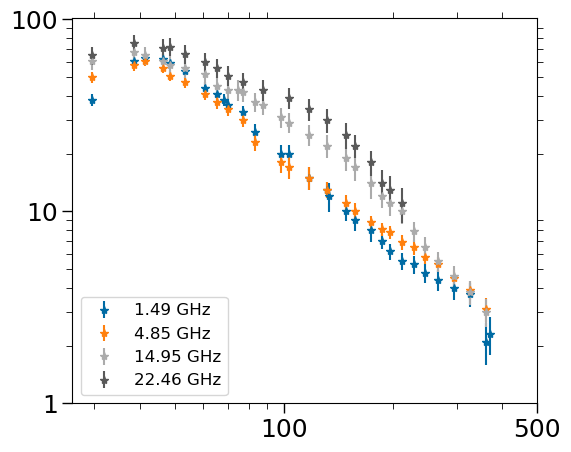

In [19]:
plt.style.use('tableau-colorblind10')

import matplotlib
%matplotlib inline


fig=plt.figure(figsize=(6,5))

ax=fig.add_subplot(111)


plt.errorbar(Det_day1_85,Det_S1_85, yerr = quad_L85, fmt= '*', label ='1.49 GHz')
plt.errorbar(Det_day2_85,Det_S2_85, yerr = quad_C85, fmt= '*', label ='4.85 GHz')
plt.errorbar(Det_day3_85,Det_S3_85, yerr = quad_K85, fmt= '*',  label ='14.95 GHz')
plt.errorbar(Det_day4_85,Det_S4_85, yerr = quad_Ku85, fmt= '*',  label ='22.46 GHz')


ax.set_xscale('log')
ax.set_yscale('log')

ax.set_xticks([100,500], labels = ['100','500'], fontsize = 18)
ax.set_yticks([1,10,100], labels = ['1','10','100'], fontsize = 18)

ax.tick_params(which='minor', length =4, top=True, labeltop=False, right=True, labelright=False,
              bottom=True, labelbottom=False, left=True, labelleft=False)

ax.tick_params(which='major', length=7, width =1,)



ax.legend(fontsize=12, loc='lower left')

plt.savefig("RS_oph_1985E.png")

plt.show()

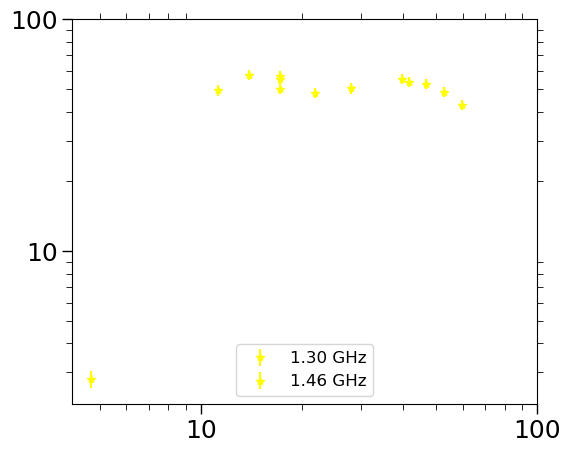

In [20]:
# 2006
plt.style.use('tableau-colorblind10')


import matplotlib
%matplotlib inline


fig=plt.figure(figsize=(6,5))

ax=fig.add_subplot(111)


#plt.scatter(ndate_B4, nflux_B4, marker='v', color='black')
#plt.errorbar(date_B3, flux_B3, yerr = quad_B3_06, fmt= 'o', label ='0.33 GHz')
plt.errorbar(date_B5, flux_B5, yerr = quad_B5_06, fmt= '*', color= 'yellow',  label ='1.30 GHz')


plt.errorbar(date_Lac, flux_Lac, yerr = quad_Lac_06, fmt= '*',color = 'yellow', label ='1.46 GHz')
#plt.errorbar(date_Cac, flux_Cac, yerr = quad_Cac_06, fmt= '*',  label ='5 GHz')
#plt.errorbar(date_Cbd, flux_Cbd, yerr = quad_Cbd_06, fmt= '*', label ='7 GHz')
#plt.errorbar(date_Kuac, flux_Kuac, yerr = quad_Kuac_06, fmt= '*', label ='15 GHz')
#plt.errorbar(date_Kubd, flux_Kubd, yerr = quad_Kubd_06, fmt= '*', label ='22 GHz')
#plt.errorbar(date_Ka, flux_Ka, yerr = quad_Ka_06, fmt= '*', label ='30 GHz')


ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xticks([10,100], labels = ['10','100'], fontsize = 18)
ax.set_yticks([10,100], labels = ['10','100'], fontsize = 18)

ax.tick_params(which='minor', length =4, top=True, labeltop=False, right=True, labelright=False,
              bottom=True, labelbottom=False, left=True, labelleft=False)

ax.tick_params(which='major', length=7, width =1,)



ax.legend(fontsize=12, loc='lower center')

plt.savefig("RS_oph_2006E.png")
plt.show()

In [21]:
#Make plots to support/disprove double peak argument in 2006 and 2021
#Make plots comparing decline from peak of eruptions 
#Make radio light curves of each eruption to include with an optical top and a spectral index below 



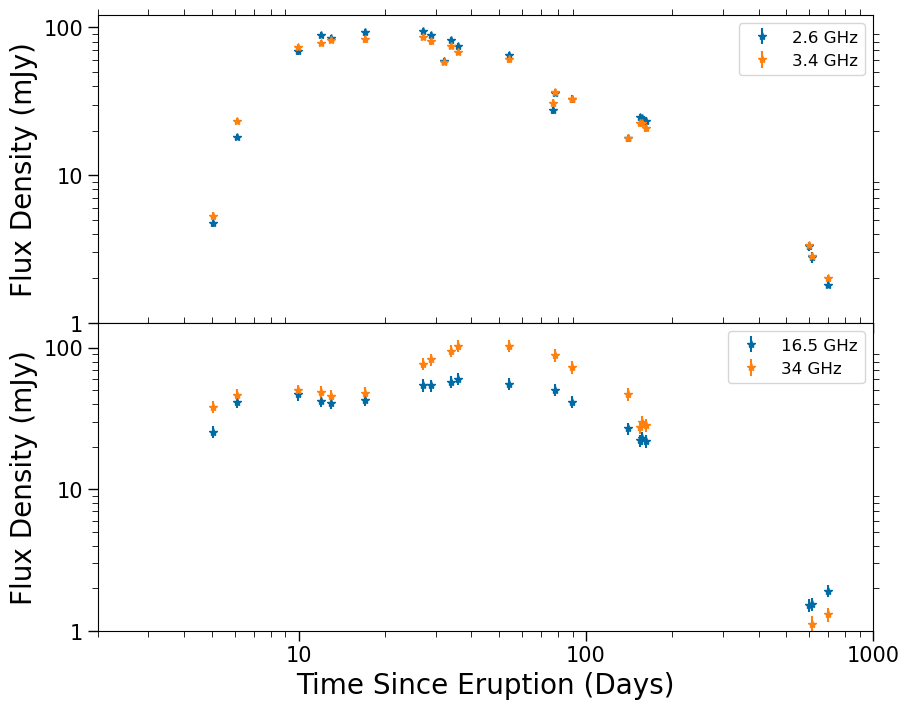

In [23]:
#plt.style.use('dark_background')
plt.style.use('tableau-colorblind10')

import matplotlib
%matplotlib inline

fig, axs = plt.subplots(2, 1, figsize=(10, 8), sharey=False, sharex = True)

axs[0].errorbar(date_LAC_21,flux_LAC_21, yerr = quad_Lac_21, fmt= '*', label ='2.6 GHz')
axs[0].errorbar(date_LBD_21,flux_LBD_21, yerr = quad_Lbd_21, fmt= '*', label ='3.4 GHz')

axs[0].set_xscale('log')
axs[0].set_yscale('log')

axs[0].set_yticks([1,10,100], labels = ['1','10','100'], fontsize = 15)
axs[1].set_ylim([1,120])

axs[0].tick_params(which='minor', length =4, top=True, labeltop=False, right=True, labelright=False,
              bottom=True, labelbottom=False, left=True, labelleft=False)

axs[0].tick_params(which='major', length=7, width =1,)

axs[0].legend(fontsize=12, loc='upper right')
axs[0].set_ylabel('Flux Density (mJy)',fontsize=20)

axs[1].errorbar(date_KuBD_21,flux_KuBD_21, yerr = quad_Kubd_21, fmt= '*', label ='16.5 GHz')
axs[1].errorbar(date_KaBD_21,flux_KaBD_21, yerr = quad_Kabd_21, fmt= '*',label ='34 GHz')

axs[1].set_xscale('log')
axs[1].set_yscale('log')


axs[1].set_xticks([10,100,1000], labels = ['10','100','1000'], fontsize = 15)
axs[1].set_yticks([1,10,100], labels = ['1','10','100'], fontsize = 15)

axs[1].set_ylim([1,150])
axs[1].set_xlim([2,1000])

axs[1].tick_params(which='minor', length =4, top=True, labeltop=False, right=True, labelright=False,
              bottom=True, labelbottom=False, left=True, labelleft=False)

axs[1].tick_params(which='major', length=7, width =1,)
axs[1].set_xlabel('Time Since Eruption (Days)', fontsize=20)
axs[1].set_ylabel('Flux Density (mJy)',fontsize=20)

axs[1].legend(fontsize=12, loc='upper right')

plt.savefig("rsoph_doublepeak.png")
fig.subplots_adjust(hspace=0.0)
plt.show()

## ALL ERUPTIONS SLOPE

Plotting ~1.49 GHz (1.49, 1.30, 1.36,1.49) 

Similar light curves for lower frequencies (when optically thin) 
Can it be explained by the WD being in a different position in the binary? The photosphere is maybe denser in the 2021 eruption?
Optically thick synchrotron


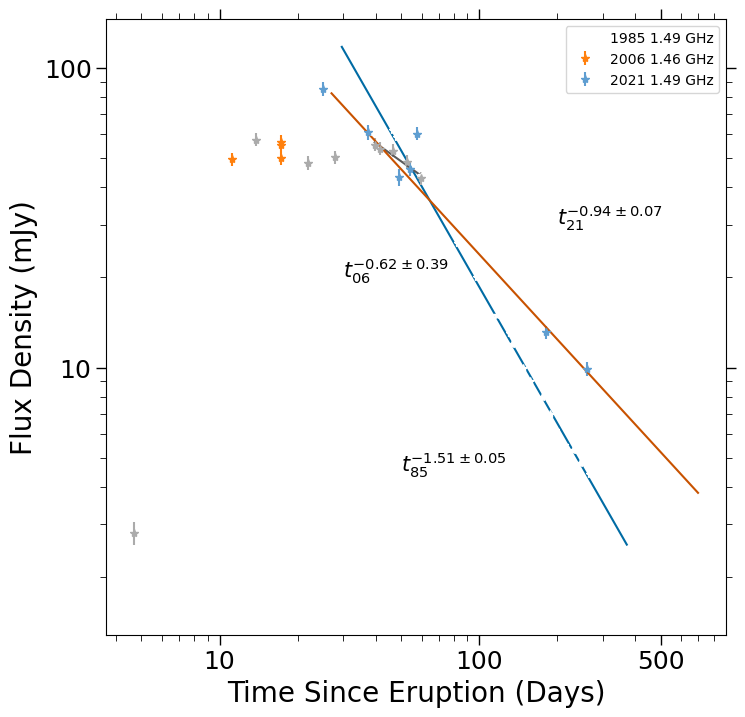

In [61]:
import matplotlib
%matplotlib inline
#plt.style.use('dark_background')
plt.style.use('tableau-colorblind10')



fig=plt.figure(figsize=(8,8))

ax=fig.add_subplot(111)
plt.errorbar(Det_day1_85,Det_S1_85, yerr = quad_L85, fmt= '*',  color = 'white', label ='1985 1.49 GHz')

plt.plot(Det_day1_85, fit_L85(Det_day1_85))

plt.annotate('$t_{85}^{-1.51 \pm 0.05}$', xy=(50,4.5), fontsize=15)

plt.errorbar(date_B5, flux_B5, yerr = quad_B5_06, fmt= '*', label ='2006 1.46 GHz')
plt.errorbar(date_Lac, flux_Lac, yerr = quad_Lac_06, fmt= '*')

plt.plot(cut_06_day, fit_06(cut_06_day))
plt.annotate('$t_{06}^{-0.62 \pm  0.39}$',  xy=(30,20), fontsize=15)


#plt.errorbar(date_LAC_21,flux_LAC_21, yerr = quad_Lac_21, fmt= '*', color='blue', label ='2021 1.49 GHz')
plt.errorbar(date_uG4,flux_uG4, yerr = quad_uG4, fmt= '*',label ='2021 1.49 GHz')

plt.plot(CUT_day_21, fit_21(CUT_day_21))

#plt.annotate('$t_{21}^{-1.34 \pm 0.01}$', color='blue', xy=(200,30), fontsize=15)
plt.annotate('$t_{21}^{-0.94 \pm 0.07}$', xy=(200,30), fontsize=15)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylabel('Flux Density (mJy)', fontsize=20)
ax.set_xlabel('Time Since Eruption (Days)', fontsize=20)

    
ax.tick_params(which = 'both', top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
ax.tick_params(which='minor', length =4)
ax.tick_params(which='major', length=7, width =1)

ax.set_xticks([10,100,500], labels = ['10','100','500'], fontsize = 18)
ax.set_yticks([10,100], labels = [r'$10$',r'$100$'], fontsize = 18)
plt.legend()

plt.savefig("slope_L.png")

plt.show()

In [28]:
#1989 Cut first 2 points and last 2 points to get slope of just the decline from peak
#2021 Cut first 5 points to get slope of just the decline from peak 
#Can use all of 2021 1.36 GHz data 
fit = fitting.LevMarLSQFitter(calc_uncertainties=True)


CUT_day_85 = Det_day1_85[2:30]
CUT_S_85 = Det_S1_85[2:30]
CUT_Q_85 = quad_L85[2:30]

CUT_day_21 = date_LAC_21[6:22]
CUT_S_21 = flux_LAC_21[6:22]
CUT_Q_21 = quad_Lac_21[6:22]




In [34]:
#remove index 8 and then 10

index_to_remove = 10
removed_element = CUT_day_85.pop(index_to_remove)
print(CUT_day_85)
print('Removed element:' ,removed_element)

[41.49000000022352, 46.52000000001863, 48.49000000022352, 53.45999999996275, 60.52000000001863, 65.39000000013039, 68.35999999986961, 70.35000000009313, 77.35000000009313, 83.29000000003725, 98.31000000005588, 103.3300000000745, 117.39999999990687, 131.37999999988824, 133.4199999999255, 148.22999999998137, 157.20999999996275, 174.1699999999255, 187.14000000013039, 196.20999999996275, 212.25, 229.1699999999255, 245.04000000003725, 267.04000000003725, 293.9900000002235, 326.7200000002049]
Removed element: 87.47999999998137


In [35]:
PL_85 =  PowerLaw1D(amplitude = CUT_S_85[0], x_0=CUT_day_85[0], alpha= 1.3) 
w1 = 1/(np.power(CUT_Q_85,2))

fit_L85 = fit(PL_85, CUT_day_85, CUT_S_85, weights=w1)

#alpha = 1.51 \pm 0.05


In [36]:
fit_L85

<PowerLaw1D(amplitude=63.68825515, x_0=44.37038394, alpha=1.51336947)>

In [37]:
cov_L85 = np.array([[7.03077614e+30, -2.42469685e+31,  6.37871354e+12],
        [-2.42469685e+31,  8.36202816e+31, -2.19982066e+13],
        [ 6.37871354e+12, -2.19982066e+13,  2.36965351e-03]])


def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)


dev_L85 = stand(cov_L85) 

print(dev_L85)


(2651561076045581.0, 9144412589116920.0, 0.048679086988151286)


In [38]:
cut_06_day = [39.62, 41.62, 46.57, 52.71, 59.74]
cut_06_Q = [2.7911691098892595,2.7066769293729904,2.6525506592711854,2.448448488328885,2.160925727552893]
cut_06_F = [55.5, 53.8, 52.9, 48.6, 42.8]

In [39]:
PL_06 = PowerLaw1D(amplitude = cut_06_F[0], x_0=cut_06_day[0], alpha= 1.4) 
w3 = 1/(np.power(cut_06_Q,2))
fit_06 = fit(PL_06, cut_06_day, cut_06_F, weights=w3)

fit_06
#\alpha=0.62 \pm  0.39

<PowerLaw1D(amplitude=54.9210204, x_0=41.38672585, alpha=0.620889)>

In [40]:
cov_06 = np.array([[ 5.88151770e+32, -7.13425841e+32,  3.69367152e+15],
        [-7.13425841e+32,  8.65382810e+32, -4.48040939e+15],
        [ 3.69367152e+15, -4.48040939e+15,  1.51995262e-01]])

dev_06 = stand(cov_06) 
print(dev_06)

(2.4251840548708876e+16, 2.9417389585073656e+16, 0.38986569738821597)


In [41]:
PL_21 = PowerLaw1D(amplitude = flux_uG4[0], x_0=date_uG4[0], alpha= 1.4) 
w2 = 1/(np.power(quad_uG4,2))
fit_21 = fit(PL_21, date_uG4, flux_uG4, weights=w2)

fit_21
#alpha= 0.94 \ 0.07
fit.fit_info


{'nfev': 16,
 'fvec': array([ 0.16877604, -0.01993625,  0.44207211, -0.60835783, -2.11625876,
         1.30743697, -0.78615275]),
 'fjac': array([[ 1.25753780e+02, -2.52656735e+00, -4.56082933e-01,
          6.53464868e-02,  3.64563571e-02,  5.66631782e-01,
          8.18961056e-01],
        [-2.52656735e+00, -4.45652586e-01, -8.04469111e-02,
          4.75399909e-01,  2.36104459e-01,  3.90646589e-02,
         -6.47301090e-01],
        [-4.56082933e-01, -8.04469111e-02,  6.33010675e-17,
          5.48086642e-01,  2.74043321e-01,  3.63107400e-01,
          5.48086642e-01]]),
 'ipvt': array([2, 1, 0], dtype=int32),
 'qtf': array([1.59844196e-05, 2.81548638e-06, 7.93365588e-01]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 2.49561698e+32, -4.50495933e+31, -7.76747064e+14],
        [-4.50495933e+31,  8.13212071e+30,  1.40214382e+14],
        [-7.76747064e+14,  1.40214382e+1

In [42]:
cov_21 = np.array([[2.49561698e+32, -4.50495933e+31, -7.76747064e+14],
        [-4.50495933e+31,  8.13212071e+30,  1.40214382e+14],
        [-7.76747064e+14,  1.40214382e+14,  4.51330000e-03]])


dev_21 = stand(cov_21) 
print(dev_21)


(1.5797521894271898e+16, 2851687344362982.5, 0.06718109853225086)


## ALL ERUPTIONS SLOPE
Plotting ~5GHz (4.85, 5, 5.1)

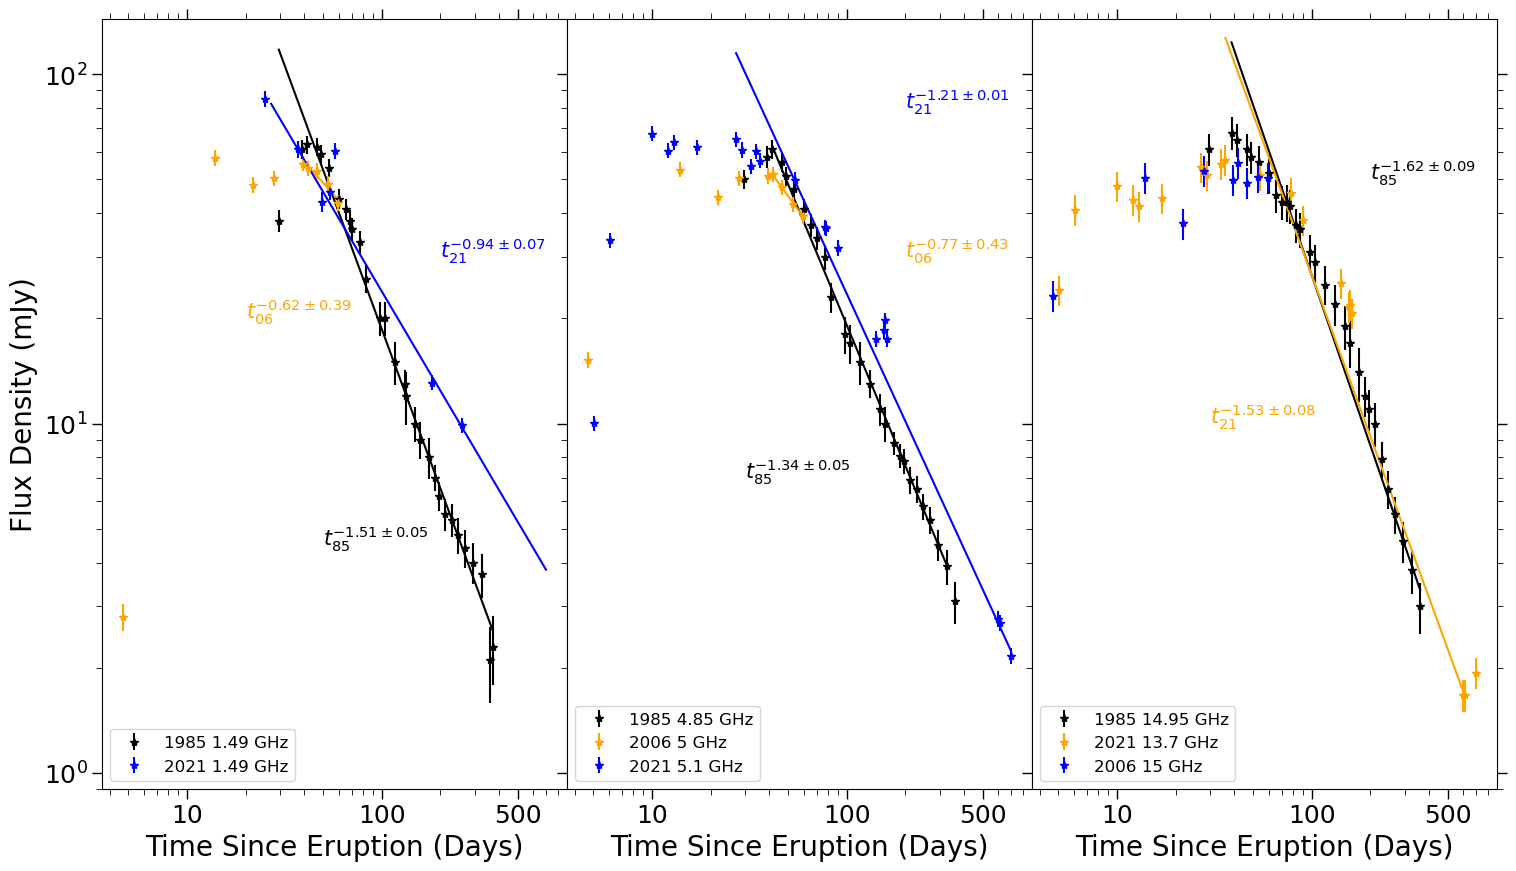

In [74]:
import matplotlib
%matplotlib inline
#from matplotlib.ticker import AutoMinorLocator

fig, axs = plt.subplots(1, 3, figsize=(18, 10), sharey=True, sharex = False)


axs[0].errorbar(Det_day1_85,Det_S1_85, yerr = quad_L85, fmt= '*',color='black', label ='1985 1.49 GHz')
axs[0].plot(Det_day1_85, fit_L85(Det_day1_85), color='black', )
axs[0].annotate('$t_{85}^{-1.51 \pm 0.05}$', xy=(50,4.5), fontsize=15, color='black')

#axs[0].errorbar(date_B5, flux_B5, yerr = quad_B5_06, fmt= '*', color='orange', label ='2006 1.46 GHz')
axs[0].errorbar(date_Lac, flux_Lac, yerr = quad_Lac_06, color='orange', fmt= '*')
axs[0].plot(cut_06_day, fit_06(cut_06_day),color='orange')
axs[0].annotate('$t_{06}^{-0.62 \pm  0.39}$', color='orange', xy=(20,20), fontsize=15)

axs[0].errorbar(date_uG4,flux_uG4, yerr = quad_uG4, color='blue', fmt= '*',label ='2021 1.49 GHz')
axs[0].plot(CUT_day_21, fit_21(CUT_day_21),color='blue')
axs[0].annotate('$t_{21}^{-0.94 \pm 0.07}$', color='blue', xy=(200,30), fontsize=15)

axs[0].set_xscale('log')
axs[0].set_yscale('log')

axs[0].set_ylabel('Flux Density (mJy)', fontsize=20)
axs[0].set_xlabel('Time Since Eruption (Days)', fontsize=20)
axs[0].legend(fontsize=12, loc='lower left')
axs[0].tick_params(which = 'major',length=7, width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False, left=True, labelleft=True)
axs[0].tick_params(which='minor', length =4, top=True,left=True,right=True,bottom=True)


axs[0].set_ylim([0.9,144])
axs[0].set_xticks([10,100,500], labels = ['10','100','500'], fontsize = 18)
axs[0].set_yticks([1,10,100], labels = ['1','10','100'], fontsize = 18)



##########
axs[1].errorbar(Det_day2_85,Det_S2_85, yerr = quad_C85, fmt= '*', color='black', label ='1985 4.85 GHz')
axs[1].plot(CUT_day2_85,fit2_85(CUT_day2_85), color = 'black')
axs[1].annotate('$t_{85}^{-1.34 \pm 0.05}$', xy=(30,7), fontsize=15)


axs[1].errorbar(date_Cac, flux_Cac, yerr = quad_Cac_06, fmt= '*', color='orange', label ='2006 5 GHz')
axs[1].plot(CUT_day2_06,fit2_06(CUT_day2_06), color = 'orange')
axs[1].annotate('$t_{06}^{-0.77 \pm 0.43}$', xy=(200,30), color = 'orange',fontsize=15)


axs[1].errorbar(date_CAB_21,flux_CAB_21, yerr = quad_Cac_21, fmt= '*', color='blue', label ='2021 5.1 GHz')
axs[1].plot(CUT_day2_21,fit2_21(CUT_day2_21), color = 'blue')
axs[1].annotate('$t_{21}^{-1.21 \pm 0.01}$', xy=(200,80), color = 'blue',fontsize=15)
axs[1].legend(fontsize=12, loc='lower left')

axs[1].set_xscale('log')
axs[1].set_yscale('log')

axs[1].tick_params(which = 'major',length=7, width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False, left=True, labelleft=False)
axs[1].tick_params(which='minor', length =4, top=True,left=True,right=True,bottom=True)
axs[1].set_xlabel('Time Since Eruption (Days)', fontsize=20)
axs[1].set_xticks([10,100,500], labels = ['10','100','500'], fontsize = 18)

#################

axs[2].errorbar(Det_day3_85, Det_S3_85, yerr = quad_K85, fmt= '*', color='black', label ='1985 14.95 GHz')
axs[2].plot(CUT_day3_85, fit3_85(CUT_day3_85), color='black')
axs[2].annotate('$t_{85}^{-1.62 \pm 0.09}$', xy=(200,50), color = 'black',fontsize=15)

axs[2].errorbar(date_KuAC_21,flux_KuAC_21, yerr = quad_Kuac_21, fmt= '*', color='orange', label ='2021 13.7 GHz')
axs[2].plot( CUT_day3_21,  fit3_21(CUT_day3_21), color='orange')
axs[2].annotate('$t_{21}^{-1.53 \pm 0.08}$', xy=(30,10), color = 'orange',fontsize=15)

axs[2].errorbar(date_Kuac, flux_Kuac, yerr = quad_Kuac_06, fmt= '*', color='blue', label ='2006 15 GHz')
axs[2].legend(fontsize=12, loc='lower left')


axs[2].set_xscale('log')
axs[2].set_yscale('log')
axs[2].tick_params(which = 'major',length=7, width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False, left=True, labelleft=False)
axs[2].tick_params(which='minor', length =4, top=True,left=True,right=True,bottom=True)

axs[2].set_xlabel('Time Since Eruption (Days)', fontsize=20)
axs[2].set_xticks([10,100,500], labels = ['10','100','500'], fontsize = 18)

plt.savefig("3panel_rsoph.png")
fig.subplots_adjust(wspace=0)

plt.show()


In [43]:
#1989 Cut first 2 points and last 2 points to get slope of just the decline from peak
#2006 Cut first 5 points to get slope of just the decline from peak 
#2021 Cut first 6 points to get slope of just the decline from peak 


CUT_day2_85 = Det_day2_85[2:30]
CUT_S2_85 = Det_S2_85[2:30]
CUT_Q2_85 = quad_C85[2:30]

CUT_day2_06 = date_Cac[5:]
CUT_S2_06 = flux_Cac[5:]
CUT_Q2_06 = quad_Cac_06[5:]


CUT_day2_21 = date_CAB_21[6:]
CUT_S2_21 = flux_CAB_21[6:]
CUT_Q2_21 = quad_Cac_21[6:]


In [55]:
#Removed values using index in this order (6, 7, 9,13)
#Had to do for S, day and Q

index_to_remove = 13

removed_element = CUT_day2_85.pop(index_to_remove)
print(CUT_day2_85)
print('Removed element:' ,removed_element)

[41.49000000022352, 46.52000000001863, 48.49000000022352, 53.45999999996275, 60.52000000001863, 65.39000000013039, 70.35000000009313, 77.35000000009313, 83.29000000003725, 98.31000000005588, 103.3300000000745, 117.39999999990687, 131.37999999988824, 148.22999999998137, 157.20999999996275, 174.1699999999255, 187.14000000013039, 196.20999999996275, 212.25, 229.1699999999255, 245.04000000003725, 267.04000000003725, 293.9900000002235, 326.7200000002049]
Removed element: 133.4199999999255


In [56]:
PL2_85 =  PowerLaw1D(amplitude = CUT_S2_85[0], x_0=CUT_day2_85[0], alpha= 1) 
w3 = 1/(np.power(CUT_Q2_85,2))

fit2_85 = fit(PL2_85, CUT_day2_85, CUT_S2_85, weights=w3)
fit2_85
#alpha = 1.34 \pm 0.05


<PowerLaw1D(amplitude=49.11626785, x_0=49.42851698, alpha=1.33830806)>

In [57]:
PL2_06 =  PowerLaw1D(amplitude = CUT_S2_06[0], x_0=CUT_day2_06[0], alpha= 1) 
w4 = 1/(np.power(CUT_Q2_06,2))

fit2_06 = fit(PL2_06, CUT_day2_06, CUT_S2_06, weights=w4)
fit2_06
#alpha = 0.77 \pm 0.43


<PowerLaw1D(amplitude=43.86171164, x_0=51.30204378, alpha=0.76644115)>

In [58]:
PL2_21 =  PowerLaw1D(amplitude = CUT_S2_21[0], x_0=CUT_day2_21[0], alpha= 1) 
w5 = 1/(np.power(CUT_Q2_21,2))

fit2_21 = fit(PL2_21, CUT_day2_21, CUT_S2_21, weights=w5)
fit2_21
#alpha = 1.21 \pm 0.01

<PowerLaw1D(amplitude=83.94794585, x_0=34.98635086, alpha=1.21185791)>

In [59]:
cov2_85 = np.array([[1.36938434e+31, -1.02972554e+31, -1.06201332e+14],
        [-1.02972554e+31,  7.74314892e+30,  7.98594090e+13],
        [-1.06201332e+14,  7.98594090e+13,  2.59980470e-03]])

cov2_06 = np.array([[6.96737169e+31, -1.06325947e+32,  6.56294466e+14],
        [-1.06325947e+32,  1.62259277e+32, -1.00154166e+15],
        [ 6.56294466e+14, -1.00154166e+15,  1.84747695e-01]])


cov2_21 = np.array([[9.22255215e+30, -3.20035565e+30,  5.18514061e+12],
        [-3.20035565e+30,  1.11056854e+30, -1.79931691e+12],
        [ 5.18514061e+12, -1.79931691e+12,  1.05490674e-04]])



dev2_85 = stand(cov2_85) 
dev2_06 = stand(cov2_06) 
dev2_21 = stand(cov2_21) 


print(dev2_85,dev2_06,dev2_21)


(3700519341930265.0, 2782651419060605.0, 0.05098828002590399) (8347078345145684.0, 1.2738103351755314e+16, 0.4298228646779973) (3036865513979833.5, 1053835157887608.1, 0.010270865299476963)


## ALL ERUPTIONS SLOPE
Plotting ~15 GHz ( 14.95, 15, 13.7 or 16.5) 

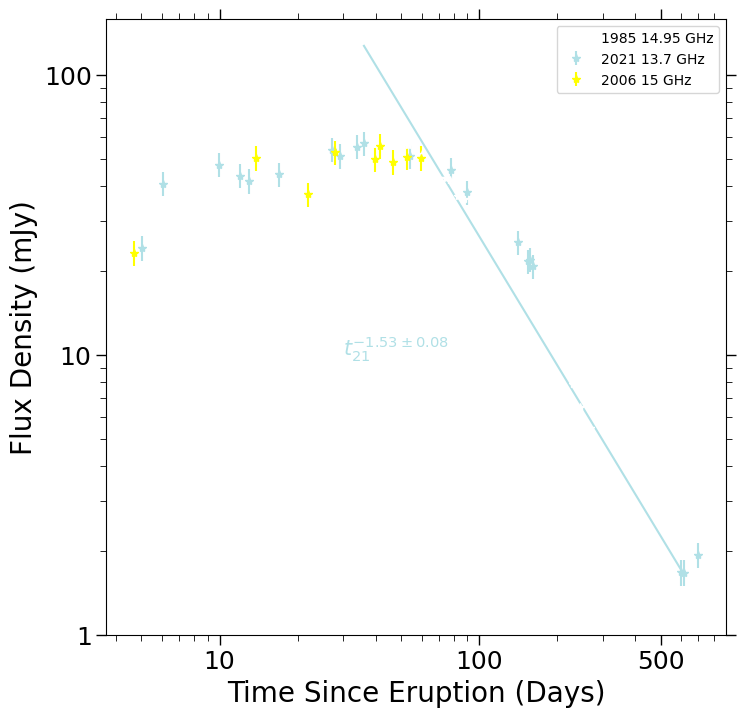

In [94]:
import matplotlib
%matplotlib inline

#plt.style.use('dark_background')
plt.style.use('tableau-colorblind10')


fig=plt.figure(figsize=(8,8))

ax=fig.add_subplot(111)
plt.errorbar(Det_day3_85, Det_S3_85, yerr = quad_K85, fmt= '*', color='white', label ='1985 14.95 GHz')
plt.plot(CUT_day3_85, fit3_85(CUT_day3_85), color='white')
plt.annotate('$t_{85}^{-1.62 \pm 0.09}$', xy=(200,50), color = 'white',fontsize=15)



plt.errorbar(date_KuAC_21,flux_KuAC_21, yerr = quad_Kuac_21, fmt= '*', color='powderblue', label ='2021 13.7 GHz')
plt.plot( CUT_day3_21,  fit3_21(CUT_day3_21), color='powderblue')
plt.annotate('$t_{21}^{-1.53 \pm 0.08}$', xy=(30,10), color = 'powderblue',fontsize=15)

plt.errorbar(date_Kuac, flux_Kuac, yerr = quad_Kuac_06, fmt= '*', color='yellow', label ='2006 15 GHz')


ax.set_xscale('log')
ax.set_yscale('log')

ax.set_ylabel('Flux Density (mJy)', fontsize=20)
ax.set_xlabel('Time Since Eruption (Days)', fontsize=20)


ax.tick_params(which = 'both', top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
ax.tick_params(which='minor', length =4)
ax.tick_params(which='major', length=7, width =1)

ax.set_xticks([10,100,500], labels = ['10','100','500'], fontsize = 18)
ax.set_yticks([1,10,100], labels = [r'$1$',r'$10$',r'$100$'], fontsize = 18)


plt.savefig("slope_Ku.png")
plt.legend()
plt.show()

In [60]:
CUT_S3_85 = Det_S3_85[1:]
CUT_day3_85 = Det_day3_85[1:]
CUT_Q3_85 = quad_K85[1:]


CUT_S3_21 = flux_KuAC_21[9:]
CUT_day3_21 = date_KuAC_21[9:]
CUT_Q3_21 = quad_Kuac_21[9:]


In [61]:
fit = fitting.LevMarLSQFitter(calc_uncertainties=True)


In [70]:
#Need to remove nans (89) from indices 7,16,28
index_to_remove = 28

removed_element = CUT_Q3_85.pop(index_to_remove)
print(CUT_Q3_85)
print('Removed element:' ,removed_element)

[7.432361670424819, 7.158910531638177, 6.419501538281614, 6.135144660071187, 6.352952069707437, 6.560487786742691, 4.924428900898052, 4.742362280551751, 5.243090691567332, 4.651881339845203, 4.205948168962618, 4.1182520563948, 3.6891733491393435, 3.5227829907617076, 3.2015621187164243, 2.973213749463701, 2.7586228448267445, 2.6248809496813377, 2.4413111231467406, 1.562049935181331, 1.4866068747318506, 1.4142135623730951, 0.9349331526906082, 0.8200609733428363, 0.6800735254367722, 0.6095900261651268, 0.5517245689653488, 0.5]
Removed element: nan


In [71]:
PL3_85 =  PowerLaw1D(amplitude = CUT_S3_85[0], x_0=CUT_day3_85[0], alpha= 1) 
w7 = 1/(np.power(CUT_Q3_85,2))

fit3_85 = fit(PL3_85, CUT_day3_85, CUT_S3_85, weights=w7)
fit.fit_info

#alpha = -1.62 \pm 0.09

cov3_85 = np.array([[ 9.81659263e+32, -2.20588033e+32,  1.06450292e+15],
        [-2.20588033e+32,  4.95681977e+31, -2.39203779e+14],
        [ 1.06450292e+15, -2.39203779e+14,  7.42832056e-03]])

dev3_85 = stand(cov3_85) 

print(dev3_85)


(3.1331442082993884e+16, 7040468571054060.0, 0.08618770538771757)


In [72]:
CUT_S3_21 = [56.891, 51.336, 45.791, 38.122, 25.248, 21.6  , 21.908, 20.702, 1.672, 1.67]

CUT_Q3_21 = [5.68942701948096,5.13413332121401,4.579406709389328,3.812514897020076,2.525688824855509,
2.160601999443674,2.191393538367767,2.070803718366374,0.174516016456943,0.173761330565808]

CUT_day3_21 = [ 36.01,  53.96,  77.92,  89.82, 140.76, 154.66, 156.61, 161.61,
       600.47, 615.34]

In [73]:
PL3_21 =  PowerLaw1D(amplitude = CUT_S3_21[0], x_0=CUT_day3_21[0], alpha=1) 
w8 = 1/(np.power(CUT_Q3_21,2))

fit3_21 = fit(PL3_21, CUT_day3_21, CUT_S3_21, weights=w8)



#alpha = -1.53 \pm 0.08
cov3_21 = np.array([[9.40846543e+31, -4.10500147e+31, -4.80826339e+14],
        [-4.10500147e+31,  1.79105054e+31,  2.09789029e+14],
        [-4.80826339e+14,  2.09789029e+14,  6.44026587e-03]])


dev3_21 = stand(cov3_21) 

print(dev3_21)


(9699724444539648.0, 4232080504905359.5, 0.08025126709280048)


## Is it Double Peaked? 

looks like it

In [73]:
freq_LAC_21

array([2.6, 2.6, 2.6, 2.6, 2.6, 2.6, 2.6, 2.6, 2.6, 2.6, 2.6, 2.6, 2.6,
       2.6, 2.6, 2.6, 2.6, 2.6, 2.6, 2.6, 2.6, 2.6])

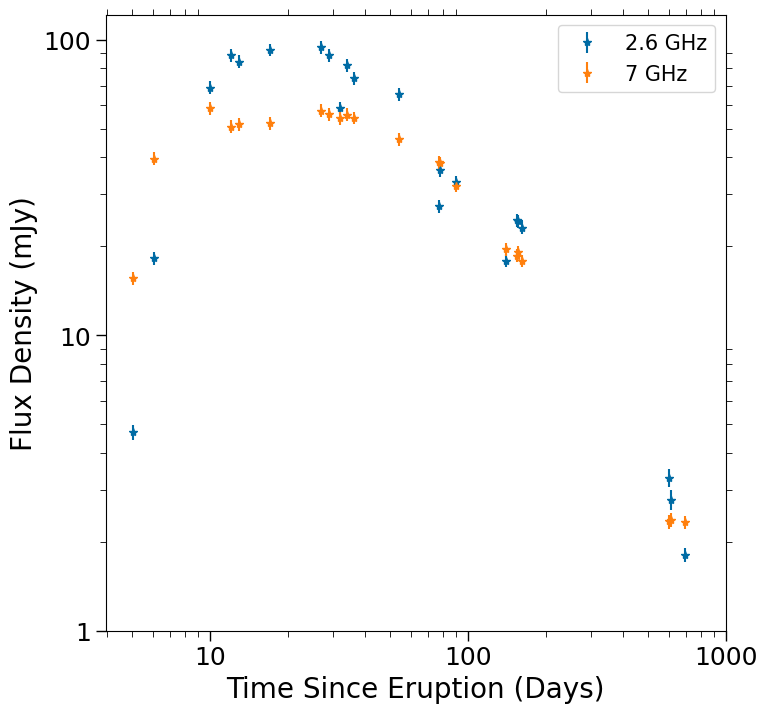

In [74]:
plt.style.use('tableau-colorblind10')

import matplotlib
%matplotlib inline

fig, axs = plt.subplots(1, 2, figsize=(15, 15), sharey=True, sharex = False)



plt.errorbar(date_LAC_21,flux_LAC_21, yerr = quad_Lac_21, fmt= '*',label ='2.6 GHz')
#plt.errorbar(date_LBD_21,flux_LBD_21, yerr = quad_Lbd_21, fmt= '*', label ='3.4 GHz')
#plt.errorbar(date_CAB_21,flux_CAB_21, yerr = quad_Cac_21, fmt= '*', label ='5.1 GHz')
plt.errorbar(date_CBD_21,flux_CBD_21, yerr = quad_Cbd_21, fmt= '*', label ='7 GHz')

ax.set_xscale('log')
ax.set_yscale('log')

ax.set_xticks([10,100,1000], labels = ['10','100','1000'], fontsize = 18)
ax.set_yticks([1,10,100], labels = ['1','10','100'], fontsize = 18)
ax.tick_params(which='minor', length =4, top=True, labeltop=False, right=True, labelright=False,
              bottom=True, labelbottom=False, left=True, labelleft=False)

ax.tick_params(which='major', length=7, width =1,)

ax.set_ylabel('Flux Density (mJy)', fontsize=20)
ax.set_xlabel('Time Since Eruption (Days)', fontsize=20)

ax.legend(fontsize=15, loc='upper right')
plt.savefig("DOUBLE_lowfreq.png")
plt.show()

## Convert JD to Calendar Date and MJD to add to Table 

In [107]:
#We have the initial date in MJD: 59434.5
#And we have the days since then 

def MJD_since(MJD, day):
    since = []
    for i in range(len(day)):
        since.append(MJD + day[i])
    return(since)

days = rs_2021b['Day']

In [108]:
mjd = MJD_since(59434.5, days)

## What Percent of the Radio Emission is Thermal? Non Thermal? 

In [29]:
# From VLBI: 1.6 and 5 GHz from 14 - 65 days after eruption 
D_1 = [15, 25, 35, 65]
D_5 = [14, 24, 34, 64]

Q1 = [1.6,1.6,1.6,1.6]
Q2 = [5,5,5,5]


#total flux in mJy
F_1 = [79.3, 64.8, 48.3, 36.7]
E_1 = [7.9, 6.5, 4.8, 3.7]

F_5 = [41.5, 43.8, 29.5, 18.0]
E_5 = [4.2, 4.4,3.0,1.8]

In [30]:
d_vla = [29.02, 32.04,  33.99,  36.01,  53.96,  76.94,  77.92,  89.82, 140.76, 154.66, 156.61, 161.61, 600.47, 615.34, 697.12]

f_vla = [60.766,54.499, 60.253, 56.608, 49.879, 36.454, 36.228, 31.849, 17.481, 18.554, 19.794, 17.488,  2.765,  2.684,  2.163]
f1_vla = [88.638,58.862, 81.96 , 74.216, 65.358, 27.414, 36.139, 32.964, 17.902, 24.59 , 24.388, 23.163,  3.295,  2.777,  1.808]

q_vla = [3.0390833963548944,2.7257735603861155,3.0132674993269353,2.830994199923412,2.4946958937914654,1.823441605865129,1.8121752012429706,
 1.5933317302118855,0.8763899831125411,0.9296382576034615,0.9916401010447288,0.876191394616496,
 0.1477060002166466,0.1442866591199616,0.10932713524098214]

q1_vla = [4.436410442012777,2.948005700469387,4.1044492931451835,3.718553030413846,3.272853557677154,
 1.3768509323815707,1.8116203527505428,1.6533188561194119,0.9171717450946688,1.2398670291607887,1.237350540469434,1.1691498717016566,
 0.23673310393774674,0.21949788723356772,0.09198456392243212]

In [33]:
#Slope of decline for 5GHz is about -0.6
#VLA 5 slope about -1.2

#Slope of decline for 1GHz is about -0.7
#VLA 1 slope about -1.3


#For VLA 5 GHz
PL_vla =  PowerLaw1D(amplitude = f_vla[0], x_0=d_vla[0], alpha= 1) 
wv = 1/(np.power(q_vla,2))
fit_V = fit(PL_vla, d_vla, f_vla, weights=wv)
#fit_V

#For VLA 1 GHz
PL1_vla =  PowerLaw1D(amplitude = f1_vla[0], x_0=d_vla[0], alpha= 1.3) 
w1v = 1/(np.power(q1_vla,2))
fit1_V = fit(PL1_vla, d_vla, f1_vla, weights=w1v)
#fit1_V

#VLBI 5 GHz 
D2_5 = [24, 34, 64]
F2_5 = [43.8, 29.5, 18.0]
E2_5 = [4.4,3.0,1.8]

PL5_vlbi =  PowerLaw1D(amplitude = F2_5[0], x_0=D2_5[0], alpha= 0.7) 
w5_vlbi = 1/(np.power(E2_5,2))
fit5_vlbi = fit(PL5_vlbi, D2_5, F2_5, weights=w5_vlbi)

#fit5_vlbi

#VLBI 1 GHz 
PL1_vlbi =  PowerLaw1D(amplitude = F_1[0], x_0=D_1[0], alpha= 0.6) 
w1_vlbi = 1/(np.power(E_1,2))
fit1_vlbi = fit(PL1_vlbi, D_1, F_1, weights=w1_vlbi)
#fit1_vlbi

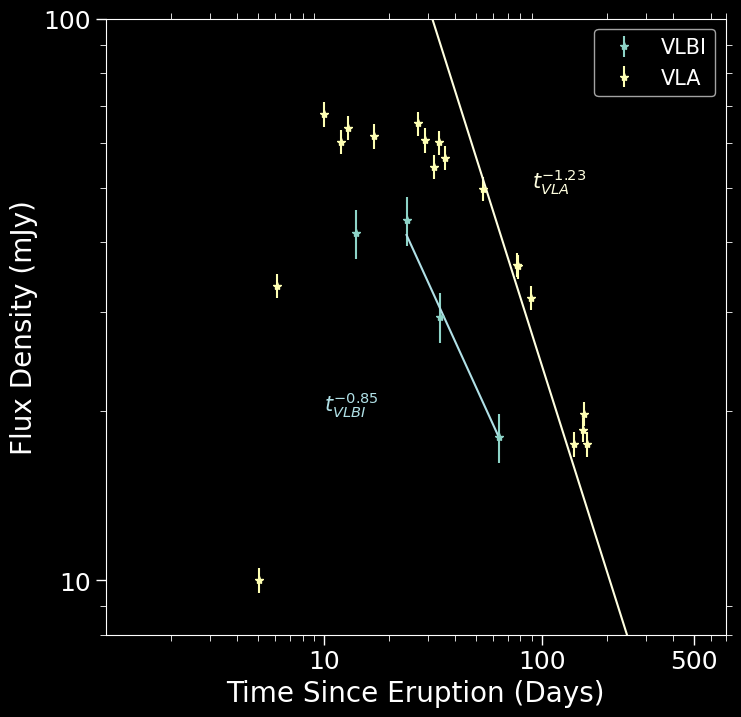

In [35]:
plt.style.use('dark_background')

import matplotlib
%matplotlib inline



fig=plt.figure(figsize=(8,8))
ax=fig.add_subplot(111)


plt.errorbar(D_5,F_5, yerr = E_5, fmt= '*',label ='VLBI')
plt.plot(D2_5,fit5_vlbi(D2_5), color='powderblue')
plt.annotate('$t_{VLBI}^{-0.85}$', xy=(10,20), color = 'powderblue',fontsize=15)


plt.errorbar(date_CAB_21,flux_CAB_21, yerr = quad_Cac_21, fmt= '*', label ='VLA')
plt.plot(d_vla, fit_V(d_vla), color='lightyellow')
plt.annotate('$t_{VLA}^{-1.23}$', xy=(90,50), color = 'lightyellow',fontsize=15)




ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xticks([10,100,500], labels = ['10','100','500'], fontsize = 18)
ax.set_yticks([10,100], labels = ['10','100'], fontsize = 18)
ax.tick_params(which='minor', length =4, top=True, labeltop=False, right=True, labelright=False, bottom=True, labelbottom=False, left=True, labelleft=False)
ax.set_ylim([8,100])
ax.set_xlim([1,700])

ax.tick_params(which='major', length=7, width =1,)

ax.set_ylabel('Flux Density (mJy)', fontsize=20)
ax.set_xlabel('Time Since Eruption (Days)', fontsize=20)

ax.legend(fontsize=15, loc='upper right')
plt.savefig("VLBA_5_VLA.png")
plt.show()


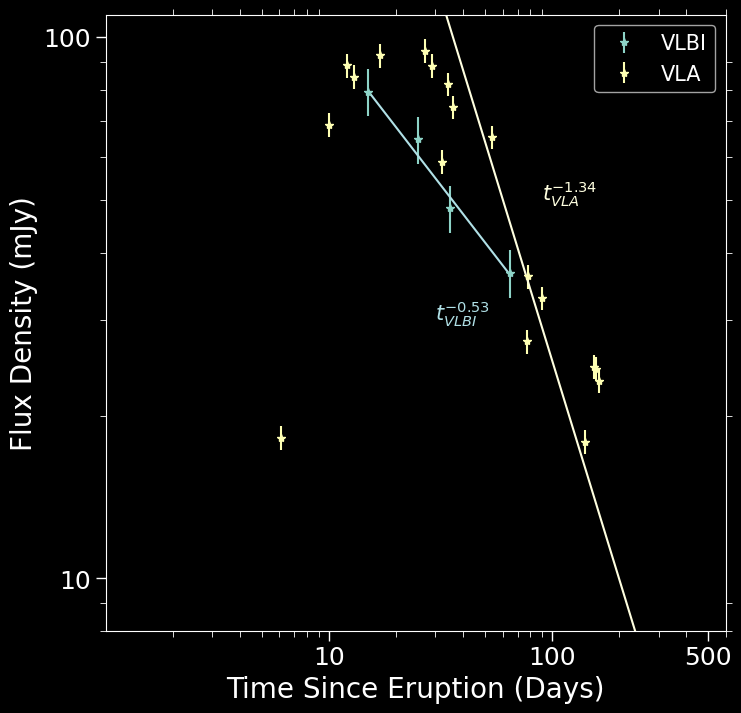

In [37]:

plt.style.use('dark_background')

import matplotlib
%matplotlib inline



fig=plt.figure(figsize=(8,8))
ax=fig.add_subplot(111)


plt.errorbar(D_1,F_1, yerr = E_1, fmt= '*',label ='VLBI')
plt.plot(D_1, fit1_vlbi(D_1), color = 'powderblue')
plt.annotate('$t_{VLBI}^{-0.53}$', xy=(30,30), color = 'powderblue',fontsize=15)


plt.errorbar(date_LAC_21,flux_LAC_21, yerr = quad_Lac_21, fmt= '*',label ='VLA')
plt.plot(d_vla, fit1_V(d_vla), color = 'lightyellow')
plt.annotate('$t_{VLA}^{-1.34}$', xy=(90,50), color = 'lightyellow',fontsize=15)




ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xticks([10,100,500], labels = ['10','100','500'], fontsize = 18)
ax.set_yticks([10,100], labels = ['10','100'], fontsize = 18)
ax.tick_params(which='minor', length =4, top=True, labeltop=False, right=True, labelright=False, bottom=True, labelbottom=False, left=True, labelleft=False)
ax.set_ylim([8,110])
ax.set_xlim([1,600])

ax.tick_params(which='major', length=7, width =1,)

ax.set_ylabel('Flux Density (mJy)', fontsize=20)
ax.set_xlabel('Time Since Eruption (Days)', fontsize=20)

ax.legend(fontsize=15, loc='upper right')
plt.savefig("VLBA_1.5_VLA.png")
plt.show()


## Spectral Index Comparison

In [62]:
#VLBI D_1 = [15, 25, 35, 65]
Q_15 = [1.6,5]
F_15 = [79.3, 41.5]

Q_25 = [1.6,5]
F_25 = [64.8, 43.8]

Q_35 = [1.6,5]
F_35 = [48.3, 29.5]

Q_65 = [1.6,5]
F_65 = [36.7, 18.0]

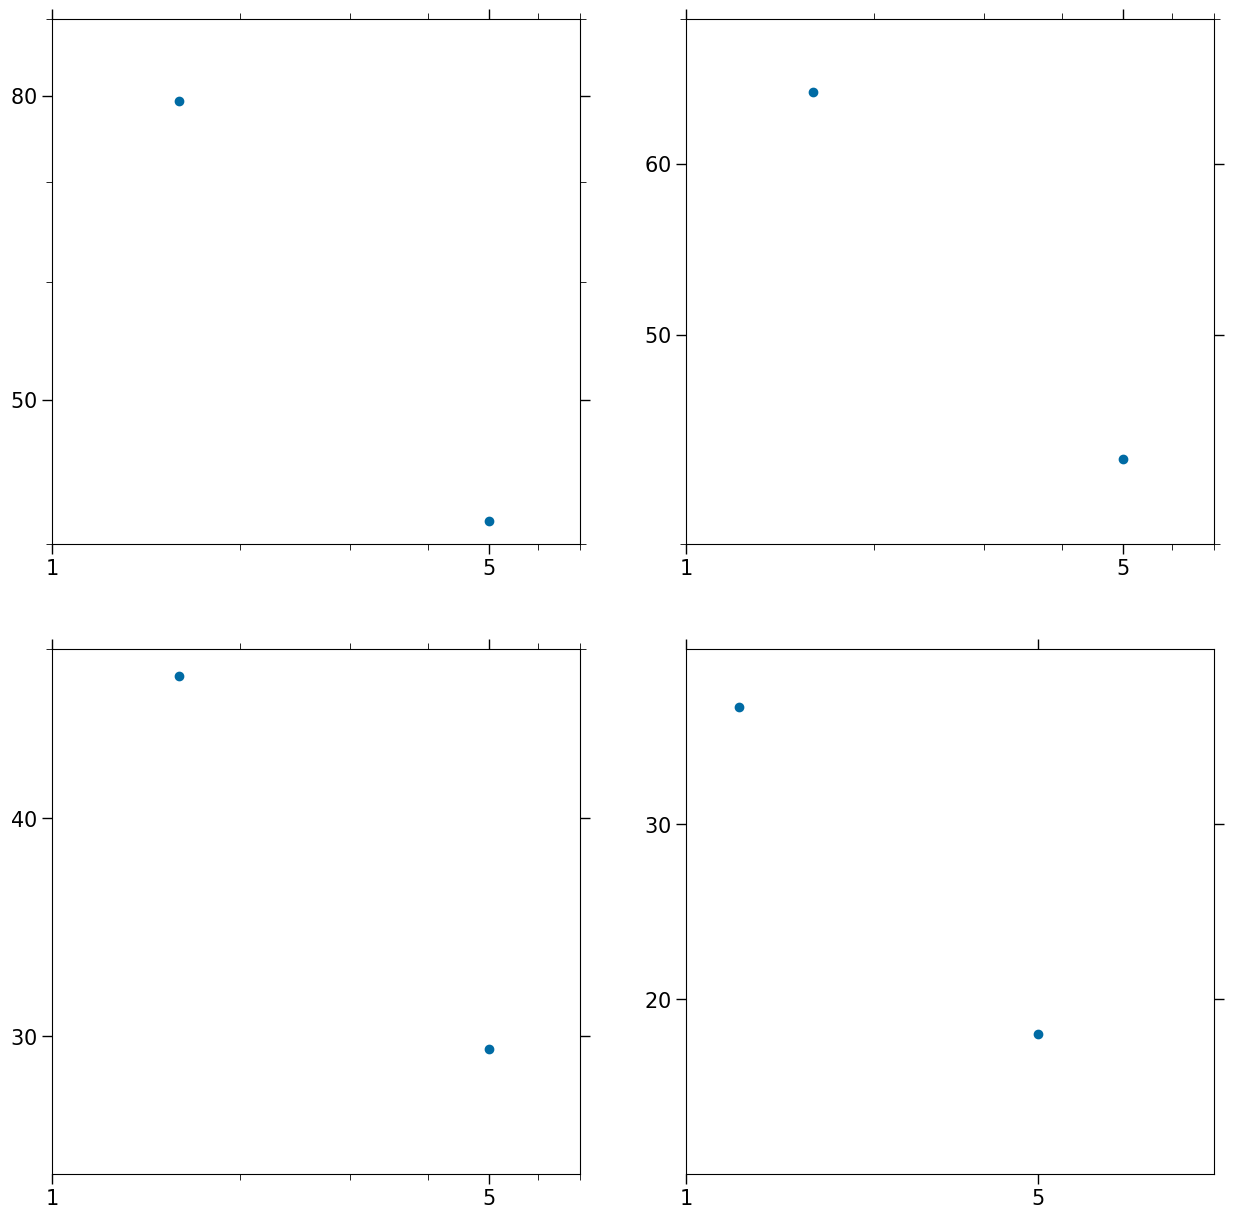

In [182]:
#Plotting freq vs flux 
plt.style.use('tableau-colorblind10')

fig, axs = plt.subplots(2, 2, figsize=(15, 15), sharey=False, sharex = False)

axs[0,0].scatter(Q_15,F_15)
axs[0,0].set_xscale('log')
axs[0,0].set_yscale('log')

axs[0,0].set_ylim([40,90])
axs[0,0].set_yticks([50,80])
axs[0,0].set_yticklabels([r'$50$',r'$80$'])

axs[0,0].set_xlim([1,7])
axs[0,0].set_xticks([1,5])
axs[0,0].set_xticklabels([r'$1$',r'$5$'])

axs[0,0].tick_params(which='minor', length =4, top=True, labeltop=False, left=True, labelleft=False, bottom=True, labelbottom=False, right = True, labelright = False)
axs[0,0].tick_params(which='major', length=7, width =1, labelsize=15, top=True, labeltop=False,left=True,labelleft=True, bottom=True, labelbottom=True, right = True, labelright = False)

axs[0,1].scatter(Q_25,F_25)
axs[0,1].set_xscale('log')
axs[0,1].set_yscale('log')

axs[0,1].set_xscale('log')
axs[0,1].set_yscale('log')

axs[0,1].set_ylim([40,70])
axs[0,1].set_yticks([50,60])
axs[0,1].set_yticklabels([r'$50$',r'$60$'])

axs[0,1].set_xlim([1,7])
axs[0,1].set_xticks([1,5])
axs[0,1].set_xticklabels([r'$1$',r'$5$'])

axs[0,1].tick_params(which='minor', length =4, top=True, labeltop=False, left=True, labelleft=False, bottom=True, labelbottom=False, right = True, labelright = False)
axs[0,1].tick_params(which='major', length=7, width =1, labelsize=15, top=True, labeltop=False,left=True,labelleft=True, bottom=True, labelbottom=True, right = True, labelright = False)


axs[1,0].scatter(Q_35,F_35)
axs[1,0].set_xscale('log')
axs[1,0].set_yscale('log')

axs[1,0].set_ylim([25,50])
axs[1,0].set_yticks([30,40])
axs[1,0].set_yticklabels([r'$30$',r'$40$'])
axs[1,0].set_xlim([1,7])
axs[1,0].set_xticks([1,5])
axs[1,0].set_xticklabels([r'$1$',r'$5$'])

axs[1,0].tick_params(which='minor', length =4, top=True, labeltop=False, left=True, labelleft=False, bottom=True, labelbottom=False, right = True, labelright = False)
axs[1,0].tick_params(which='major', length=7, width =1, labelsize=15, top=True, labeltop=False,left=True,labelleft=True, bottom=True, labelbottom=True, right = True, labelright = False)

axs[1,1].scatter(Q_65,F_65)

axs[1,1].set_ylim([10,40])
axs[1,1].set_yticks([20,30])
axs[1,1].set_yticklabels([r'$20$',r'$30$'])

axs[1,1].set_xlim([1,7])
axs[1,1].set_xticks([1,5])
axs[1,1].set_xticklabels([r'$1$',r'$5$'])

axs[1,1].tick_params(which='minor', length =4, top=True, labeltop=False, left=True, labelleft=False, bottom=True, labelbottom=False, right = True, labelright = False)
axs[1,1].tick_params(which='major', length=7, width =1, labelsize=15, top=True, labeltop=False,left=True,labelleft=True, bottom=True, labelbottom=True, right = True, labelright = False)



plt.show()



In [63]:
def two_points(s1, s2, nu1, nu2,e1, e2):
    
    alpha = (np.log10(s1/s2)) / (np.log10(nu1/nu2))
    
    
    der_s1 = 1 / (s1 * np.log(nu1/nu2))
    der_s2 = -1 / (s2 * np.log(nu1/nu2))
    
    
    err_alph_squared = (der_s1)**2 * (e1**2) + (der_s2)**2 * (e2**2) 
    err_alph = np.sqrt(err_alph_squared)
    
    return(alpha, err_alph)

In [64]:
slope1 = two_points(F_15[0],F_15[1],Q_15[0], Q_15[1], E_1[0],E_5[0])

slope2 = two_points(F_25[0],F_25[1],Q_25[0], Q_25[1], E_1[1],E_5[1])

slope3 = two_points(F_35[0],F_35[1],Q_35[0], Q_35[1], E_1[2],E_5[2])

slope4 = two_points(F_65[0],F_65[1],Q_65[0], Q_65[1], E_1[3],E_5[3])

print(slope1)
print(slope2)
print(slope3)
print(slope4)

(-0.5683036845198217, 0.12463219752593194)
(-0.34374232174220065, 0.12459035113913507)
(-0.4327070938511037, 0.12479006381933795)
(-0.6252269285516919, 0.1246237288048904)


In [20]:
#VLA: Days 15, 25, 35, 65

Day17 = np.logical_and(a_21_day>= 15.0, a_21_day<= 18.0)        
Day25 = np.logical_and(a_21_day>= 25.0, a_21_day<= 29.0)     
Day35 = np.logical_and(a_21_day>= 34.0, a_21_day<= 38.0)     
Day65 = np.logical_and(a_21_day>= 74.0, a_21_day<= 77.0)    


A  = np.where(np.logical_and(Day17, a_21_S > 3*a_21_E))   #
B  = np.where(np.logical_and(Day25, a_21_S > 3*a_21_E))   #
C  = np.where(np.logical_and(Day35, a_21_S > 3*a_21_E))   #
D  = np.where(np.logical_and(Day65, a_21_S > 3*a_21_E))   #



freq_A = np.ravel([a_21_F[i] for i in A])
flux_A = np.ravel([a_21_S[i] for i in A])
err_A  = np.ravel([a_21_E[i] for i in A])
date_A = np.ravel([a_21_day[i] for i in A])

freq_B = np.ravel([a_21_F[i] for i in B])
flux_B = np.ravel([a_21_S[i] for i in B])
err_B  = np.ravel([a_21_E[i] for i in B])
date_B = np.ravel([a_21_day[i] for i in B])

freq_C = np.ravel([a_21_F[i] for i in C])
flux_C = np.ravel([a_21_S[i] for i in C])
err_C  = np.ravel([a_21_E[i] for i in C])
date_C = np.ravel([a_21_day[i] for i in C])

freq_D = np.ravel([a_21_F[i] for i in D])
flux_D = np.ravel([a_21_S[i] for i in D])
err_D  = np.ravel([a_21_E[i] for i in D])
date_D = np.ravel([a_21_day[i] for i in D])

In [23]:
freq_C

array([ 2.6,  3.4,  5.1,  7. , 13.7, 16.5, 31.1, 34.9])

In [106]:
#Initialize fitters
fitBPL = fitting.LevMarLSQFitter(calc_uncertainties=True)
print(fitBPL.fit_info)


{'nfev': None, 'fvec': None, 'fjac': None, 'ipvt': None, 'qtf': None, 'message': None, 'ierr': None, 'param_jac': None, 'param_cov': None}


In [107]:
def bpl_func(freq, flux, er, a1, a2):
    wt = 1 / (np.power(er,2))
    peak = np.max(flux)
    BPL = []
    
    for i in range(0,len(freq)):
        for j in range(0,len(a1)):
            bro = BrokenPowerLaw1D(peak, freq[i], alpha_1 = a1[j], alpha_2 = a2[j])
            BPL.append(bro)
        
        
    return(BPL)

In [124]:
x_val = np.arange(0.1,40,0.5)
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)


In [125]:
BF9 = bpl_func(x_val, flux_A, err_A, a1, a2)

BF10 = bpl_func(x_val, flux_B, err_B, a1, a2)

BF11 = bpl_func(x_val, flux_C, err_C, a1, a2)


In [126]:
w1 = 1/ (np.power(err_A,2)) 
w2 = 1/ (np.power(err_B,2)) 
w3 = 1/ (np.power(err_C,2)) 
w4 = 1/ (np.power(err_D,2)) 


In [173]:
fw_tBPL1 = fitBPL(BF9[88], freq_A, flux_A, weights=w1)          
fw_tBPL1

<BrokenPowerLaw1D(amplitude=42.2731038, x_break=14.97279663, alpha_1=0.32458285, alpha_2=-0.14985399)>

In [153]:
fw_tBPL2 = fitBPL(BF10[80], freq_B, flux_B, weights=w2)           
fw_tBPL2

<BrokenPowerLaw1D(amplitude=48.47591188, x_break=10.13629552, alpha_1=0.44999471, alpha_2=-0.30261281)>

In [175]:
fw_tBPL3 = fitBPL(BF11[82], freq_C, flux_C, weights=w3)           
fw_tBPL3

<BrokenPowerLaw1D(amplitude=49.72785074, x_break=11.42998097, alpha_1=0.17355206, alpha_2=-0.60434343)>

In [187]:
PLM =  PowerLaw1D(amplitude = flux_D[0], x_0=freq_D[0], alpha= 0.23) 
fitPLM = fitBPL(PLM, freq_D, flux_D, weights= 1/ (np.power(err_D,2)))

fitPLM

<PowerLaw1D(amplitude=34.92374901, x_0=4.58440399, alpha=-0.25283635)>

In [181]:
#fitBPL.fit_info
#BPL1 a1= -0.32458285 and a2= 0.14985399
#BPL2 a1= -0.44999471 and a2= 0.30261281
#BPL3 a1= -0.17355206 and  a2= 0.60434343
#PL  alpha = 0.25283635

In [189]:

cov_A = np.array([[ 1.00031463e-05, -7.73378867e-06, -8.00989910e-08,
          6.78539358e-07],
        [-7.73378867e-06,  1.59598107e-05, -1.89320346e-07,
         -7.40435771e-07],
        [-8.00989910e-08, -1.89320346e-07,  1.03730242e-08,
         -2.00420472e-26],
        [ 6.78539358e-07, -7.40435771e-07, -2.00420472e-26,
          1.29061703e-07]])


cov_B = np.array([[ 2.06989127e-05, -4.70339023e-06,  2.17192755e-07,
          4.13218969e-07],
        [-4.70339023e-06,  4.66357392e-06, -1.02487880e-06,
         -7.79174664e-08],
        [ 2.17192755e-07, -1.02487880e-06,  3.35049827e-07,
          1.69912366e-23],
        [ 4.13218969e-07, -7.79174664e-08,  1.69912366e-23,
          1.15154268e-08]])


cov_C = np.array([[ 3.78323492e-05,  1.30599551e-05, -1.36096085e-06,
          1.42173677e-07],
        [ 1.30599551e-05,  6.72704303e-06, -5.17615902e-07,
         -1.88292778e-07],
        [-1.36096085e-06, -5.17615902e-07,  5.35968751e-08,
          1.17593849e-24],
        [ 1.42173677e-07, -1.88292778e-07,  1.17593849e-24,
          3.76463449e-08]])

cov_PL = np.array([[4.95176016e+27, 2.57214627e+27, 3.35332367e+10],
        [2.57214627e+27, 1.33607772e+27, 1.74185314e+10],
        [3.35332367e+10, 1.74185314e+10, 2.80378003e-07]])

In [190]:
def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])   
    sd2 = np.sqrt(diag[1])  
    sd3 = np.sqrt(diag[2])  #Err1   
    sd4 = np.sqrt(diag[3])  #Err2
    return(sd1,sd2,sd3,sd4)


def stand2(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])   
    sd2 = np.sqrt(diag[1])  
    sd3 = np.sqrt(diag[2])  #Err1   
    return(sd1,sd2,sd3)

In [191]:
dev_A = stand(cov_A)

dev_B = stand(cov_B)

dev_C = stand(cov_C)

dev_D = stand2(cov_PL)

print(dev_A)
print(dev_B)
print(dev_C)
print(dev_D)

(0.003162775094754605, 0.003994973178883683, 0.00010184804465476989, 0.0003592515873312183)
(0.004549605774130326, 0.0021595309490720434, 0.0005788348875111106, 0.00010730995666758979)
(0.0061508006958444035, 0.0025936543775144753, 0.00023150998920133014, 0.00019402666028151905)
(70368744197974.7, 36552396911830.555, 0.0005295073210069904)


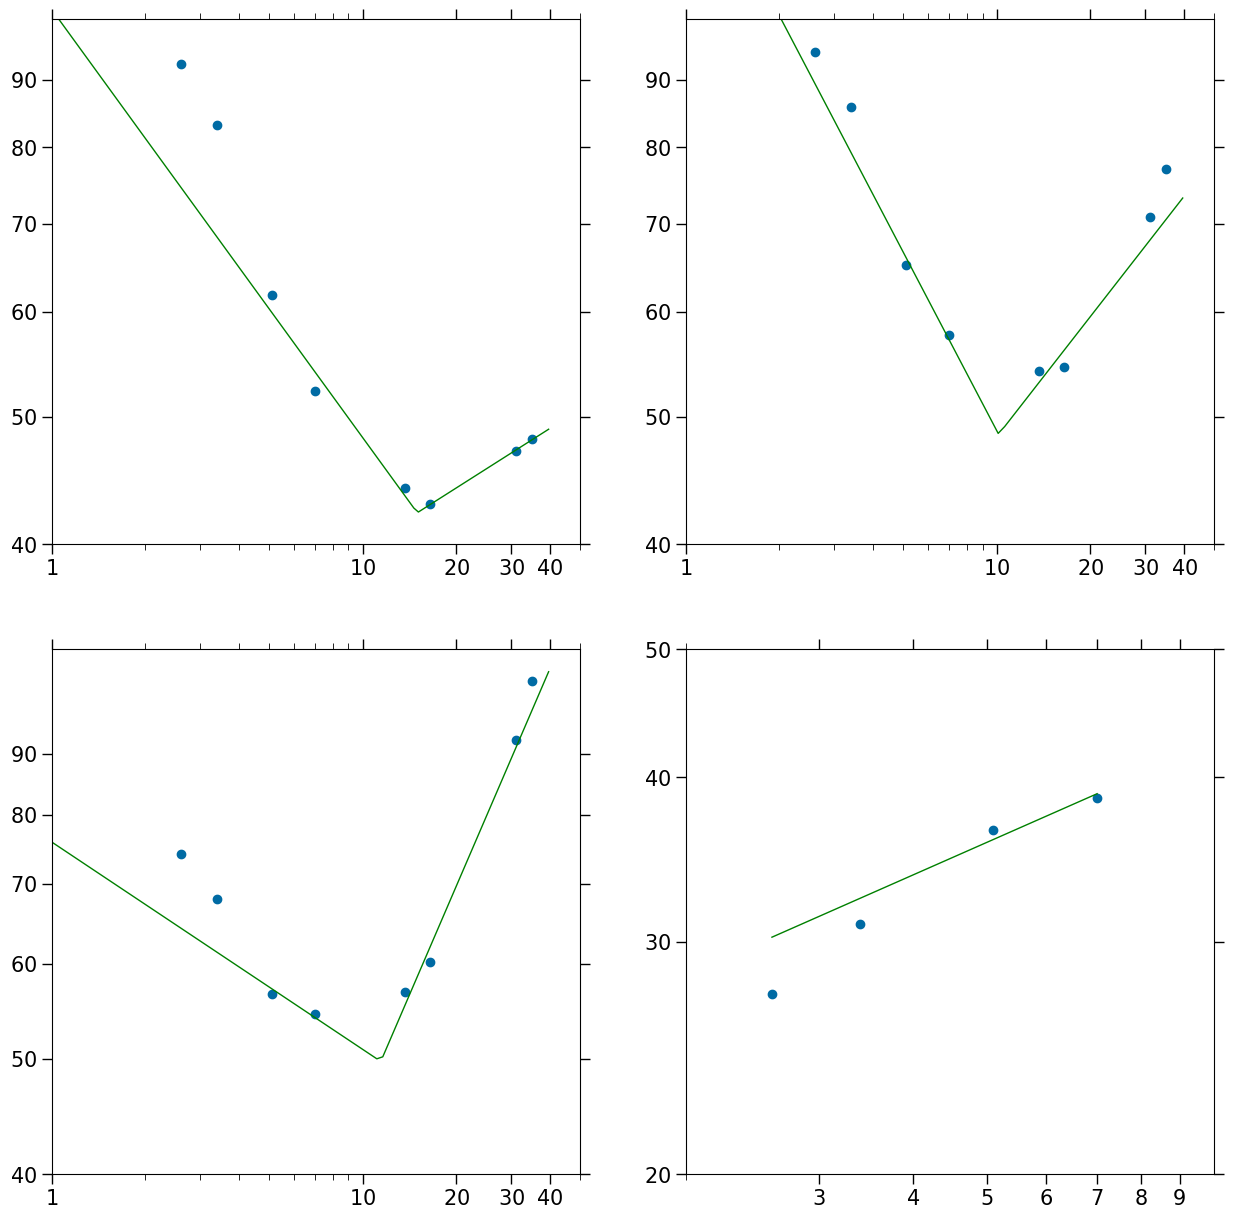

In [172]:
#Plotting freq vs flux 
plt.style.use('tableau-colorblind10')

fig, axs = plt.subplots(2, 2, figsize=(15, 15), sharey=False, sharex = False)

axs[0,0].scatter(freq_A,flux_A)
axs[0,0].plot(x_val, fw_tBPL1(x_val),'g-', linewidth=1.0)

axs[0,0].set_xscale('log')
axs[0,0].set_yscale('log')

axs[0,0].set_ylim([40,100])
axs[0,0].set_yticks([40,50,60,70,80,90])
axs[0,0].set_yticklabels([r'$40$',r'$50$',r'$60$',r'$70$',r'$80$',r'$90$'])

axs[0,0].set_xlim([1,50])
axs[0,0].set_xticks([1,10,20,30,40])
axs[0,0].set_xticklabels([r'$1$',r'$10$',r'$20$',r'$30$',r'$40$'])

axs[0,0].tick_params(which='minor', length =4, top=True, labeltop=False, left=True, labelleft=False, bottom=True, labelbottom=False, right = True, labelright = False)
axs[0,0].tick_params(which='major', length=7, width =1, labelsize=15, top=True, labeltop=False,left=True,labelleft=True, bottom=True, labelbottom=True, right = True, labelright = False)

axs[0,1].scatter(freq_B,flux_B)
axs[0,1].plot(x_val, fw_tBPL2(x_val),'g-', linewidth=1.0)

axs[0,1].set_xscale('log')
axs[0,1].set_yscale('log')

axs[0,1].set_xscale('log')
axs[0,1].set_yscale('log')

axs[0,1].set_ylim([40,100])
axs[0,1].set_yticks([40,50,60,70,80,90])
axs[0,1].set_yticklabels([r'$40$',r'$50$',r'$60$',r'$70$',r'$80$',r'$90$'])

axs[0,1].set_xlim([1,50])
axs[0,1].set_xticks([1,10,20,30,40])
axs[0,1].set_xticklabels([r'$1$',r'$10$',r'$20$',r'$30$',r'$40$'])

axs[0,1].tick_params(which='minor', length =4, top=True, labeltop=False, left=True, labelleft=False, bottom=True, labelbottom=False, right = True, labelright = False)
axs[0,1].tick_params(which='major', length=7, width =1, labelsize=15, top=True, labeltop=False,left=True,labelleft=True, bottom=True, labelbottom=True, right = True, labelright = False)


axs[1,0].scatter(freq_C,flux_C)
axs[1,0].plot(x_val, fw_tBPL3(x_val),'g-', linewidth=1.0)

axs[1,0].set_xscale('log')
axs[1,0].set_yscale('log')

axs[1,0].set_ylim([40,110])
axs[1,0].set_yticks([40,50,60,70,80,90])
axs[1,0].set_yticklabels([r'$40$',r'$50$',r'$60$',r'$70$',r'$80$',r'$90$'])

axs[1,0].set_xlim([1,50])
axs[1,0].set_xticks([1,10,20,30,40])
axs[1,0].set_xticklabels([r'$1$',r'$10$',r'$20$',r'$30$',r'$40$'])

axs[1,0].tick_params(which='minor', length =4, top=True, labeltop=False, left=True, labelleft=False, bottom=True, labelbottom=False, right = True, labelright = False)
axs[1,0].tick_params(which='major', length=7, width =1, labelsize=15, top=True, labeltop=False,left=True,labelleft=True, bottom=True, labelbottom=True, right = True, labelright = False)

axs[1,1].scatter(freq_D,flux_D)
axs[1,1].plot(freq_D, fitPLM(freq_D),'g-', linewidth=1.0)

axs[1,1].set_xscale('log')
axs[1,1].set_yscale('log')

axs[1,1].set_ylim([20,50])
axs[1,1].set_yticks([20,30,40,50])
axs[1,1].set_yticklabels([r'$20$',r'$30$',r'$40$',r'$50$'])

axs[1,1].set_xlim([2,10])
axs[1,1].set_xticks([3,4,5,6,7,8,9])
axs[1,1].set_xticklabels(['3','4','5','6','7','8','9'])

axs[1,1].tick_params(which='minor', length =4, top=True, labeltop=False, left=True, labelleft=False, bottom=True, labelbottom=False, right = True, labelright = False)
axs[1,1].tick_params(which='major', length=7, width =1, labelsize=15, top=True, labeltop=False,left=True,labelleft=True, bottom=True, labelbottom=True, right = True, labelright = False)



plt.show()

In [20]:
#optical data input

rsoph_opt_unflitered = pd.read_csv('aavsodata_6908b40cd277e.txt', header = 0)

#now to get only the vband

column_name = 'Band'
key = 'V'

rsoph_opt_kinda = rsoph_opt_unflitered[rsoph_opt_unflitered[column_name].str.contains(key, na=False)]

rsoph_opt_close = rsoph_opt_kinda[~rsoph_opt_kinda[column_name].str.contains('Vis.|CV', na=False)]

rsoph_opt =  rsoph_opt_close[~rsoph_opt_kinda["Magnitude"].str.contains('<9.1', na=False)]

rsoph_opt

/var/folders/xv/dvsld6lx4xs_nbgh_qcl11d00000gn/T/ipykernel_87720/77487244.py:14: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  rsoph_opt =  rsoph_opt_close[~rsoph_opt_kinda["Magnitude"].str.contains('<9.1', na=False)]


,JD,Magnitude,Uncertainty,HQuncertainty,Band,Observer Code,Comment Code(s),Comp Star 1,Comp Star 2,Charts,...,Cmag,Kmag,HJD,Star Name,Observer Affiliation,Measurement Method,Grouping Method,ADS Reference,Digitizer,Credit
6,2.459433e+06,11.121,0.011,NaN,V,FJQ,NaN,000-BBZ-422,000-BBZ-440,X26828BJ,...,13.598,15.373,NaN,RS OPH,AAVSO,STD,121.0,NaN,NaN,NaN
7,2.459433e+06,11.157,0.011,NaN,V,FJQ,NaN,000-BBZ-422,000-BBZ-440,X26828BJ,...,13.579,15.323,NaN,RS OPH,AAVSO,STD,122.0,NaN,NaN,NaN
8,2.459433e+06,11.109,0.012,NaN,V,FJQ,NaN,000-BBZ-422,000-BBZ-440,X26828BJ,...,13.609,15.370,NaN,RS OPH,AAVSO,STD,123.0,NaN,NaN,NaN
9,2.459433e+06,11.117,0.013,NaN,V,FJQ,NaN,000-BBZ-422,000-BBZ-440,X26828BJ,...,13.597,15.325,NaN,RS OPH,AAVSO,STD,124.0,NaN,NaN,NaN
10,2.459433e+06,11.083,0.013,NaN,V,FJQ,NaN,000-BBZ-422,000-BBZ-440,X26828BJ,...,13.605,15.422,NaN,RS OPH,AAVSO,STD,125.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10883,2.460130e+06,11.041,0.018,NaN,V,FJQ,NaN,000-BBZ-422,000-BBZ-440,X34999FB,...,14.579,16.319,NaN,RS OPH,AAVSO,STD,217.0,NaN,NaN,NaN
10891,2.460131e+06,10.991,0.003,NaN,V,FJQ,NaN,000-BBZ-422,000-BBZ-440,X34999FB,...,13.281,15.031,NaN,RS OPH,AAVSO,STD,218.0,NaN,NaN,NaN
10892,2.460131e+06,10.990,0.003,NaN,V,FJQ,NaN,000-BBZ-422,000-BBZ-440,X34999FB,...,13.262,15.031,NaN,RS OPH,AAVSO,STD,219.0,NaN,NaN,NaN
10893,2.460131e+06,10.998,0.003,NaN,V,FJQ,NaN,000-BBZ-422,000-BBZ-440,X34999FB,...,13.265,15.048,NaN,RS OPH,AAVSO,STD,220.0,NaN,NaN,NaN


In [21]:


#MJD/t0 = 59434
#JD = 2459434

opticaldays = ((rsoph_opt['JD'].astype(float)) - 2459434)
vmag = rsoph_opt['Magnitude'].astype(float)
error_vmag = rsoph_opt['Uncertainty'].astype(float)



In [72]:
freq_LAC_21

array([2.6, 2.6, 2.6, 2.6, 2.6, 2.6, 2.6, 2.6, 2.6, 2.6, 2.6, 2.6, 2.6,
       2.6, 2.6, 2.6, 2.6, 2.6, 2.6, 2.6, 2.6, 2.6])

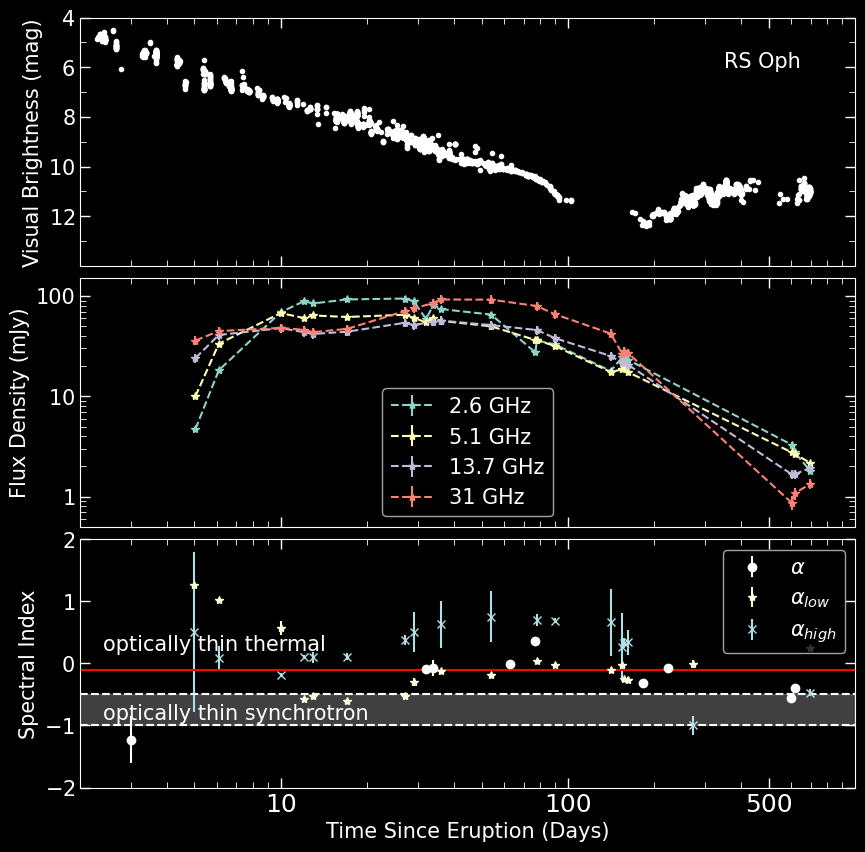

In [26]:
#plt.style.use('dark_background')

from matplotlib.ticker import AutoMinorLocator

fig, axs = plt.subplots(3, 1, figsize=(10, 10), sharey=False, sharex = True)#, constrained_layout=True)


#first the visual
axs[0].scatter(opticaldays, vmag, marker = '.', color = 'white')
axs[0].annotate('RS Oph',(350,6), fontsize=15)

axs[0].set_xscale('log')
#axs[0].set_yscale('log')

axs[0].set_ylabel('Visual Brightness (mag)',fontsize =15)

axs[0].set_yticks([4,6,8,10,12], labels = [r'$4$',r'$6$',r'$8$',r'$10$', r'$12$'], fontsize = 15)
axs[0].set_ylim(4,14)
axs[0].invert_yaxis()
axs[0].tick_params(which='minor', length=4, direction = 'in', top=True, labeltop=False, left=True, labelleft=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[0].yaxis.set_minor_locator(AutoMinorLocator(2))  # 2 minor intervals between major ticks
axs[0].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)

#now the radio
axs[1].set_ylabel('Flux Density (mJy)',fontsize=15)
axs[1].set_xscale('log')
axs[1].set_yscale('log')



axs[1].errorbar(date_LAC_21,flux_LAC_21, yerr = quad_Lac_21,linestyle='--', fmt= '*',label ='2.6 GHz')
#plt.errorbar(date_LBD_21,flux_LBD_21, yerr = quad_Lbd_21, fmt= '*', label ='3.4 GHz')
axs[1].errorbar(date_CAB_21,flux_CAB_21, yerr = quad_Cac_21, linestyle='--', fmt= '*', label ='5.1 GHz')
#plt.errorbar(date_CBD_21,flux_CBD_21, yerr = quad_Cbd_21, fmt= '*', label ='7 GHz')
axs[1].errorbar(date_KuAC_21,flux_KuAC_21, yerr = quad_Kuac_21,linestyle='--',  fmt= '*', label ='13.7 GHz')
#plt.errorbar(date_KuBD_21,flux_KuBD_21, yerr = quad_Kubd_21, fmt= '*', label ='16.5 GHz')
axs[1].errorbar(date_KaAC_21,flux_KaAC_21, yerr = quad_Kaac_21,linestyle='--',  fmt= '*', label ='31 GHz')
#plt.errorbar(date_KaBD_21,flux_KaBD_21, yerr = quad_Kabd_21, fmt= '*',label ='34 GHz')

axs[1].scatter(ndate_LBD_21, nflux_LBD_21, marker = 'v')
axs[1].scatter(ndate_CAB_21, nflux_CAB_21, marker = 'v')
axs[1].scatter(ndate_KuAC_21,nflux_KuAC_21, marker = 'v')


axs[1].legend(fontsize=15, loc='lower center')
axs[1].set_yticks([1,10,100], labels = [r'$1$',r'$10$','100'], fontsize = 15)
axs[1].set_ylim([0.5,150])

axs[1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[1].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)

########### Panel 3 ############

axs[2].errorbar(alpha_day, alpha, yerr=alpha_err, marker = 'o',  linestyle = '', color = 'white', label=r'$\alpha$')
axs[2].errorbar(a1_day, a1, yerr=a1_err, marker = '*', linestyle = '', color = 'lightyellow', label=r'$\alpha_{low}$')
axs[2].errorbar(a1_day, a2, yerr=a2_err, marker = 'x', linestyle = '',color = 'powderblue', label=r'$\alpha_{high}$')



axs[2].axhline(y = -0.1, color = 'red', linestyle = '-')
axs[2].axhline(y = -0.5, color = 'white', linestyle = '--')
axs[2].axhline(y = -1, color = 'white', linestyle = '--')
axs[2].fill_between(x=[0.1,1000],y1=-0.5,y2=-1, color = 'grey', alpha=.5)

axs[2].set_xlabel('Time Since Eruption (Days)', fontsize=15)
axs[2].set_ylabel('Spectral Index', fontsize=15)
axs[2].annotate('optically thin thermal', (2.4,0.2), fontsize=15)
axs[2].annotate('optically thin synchrotron', (2.4,-0.9), fontsize=15)

axs[2].set_xticks([10,100,500], labels = ['10','100','500'], fontsize = 18)
axs[2].set_yticks([-2,-1,0,1,2], labels = [r'$-2$',r'$-1$',r'$0$',r'$1$',r'$2$'], fontsize = 15)
axs[2].set_ylim(-2,2)
axs[2].set_xlim(2,1000)

axs[2].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[2].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
axs[2].legend(fontsize=15, loc='upper right')




fig.subplots_adjust(hspace=0.05)
plt.savefig("RSOph_RadioOptical_lightcurves.png")
plt.show();

In [24]:
alpha_day = [3, 32.04, 33.99,63, 76.94, 182, 223, 600, 615.34]
alpha = [-1.23, -0.09, -0.07, -0.01, 0.36, -0.32, -0.07, -0.55, -0.39]
alpha_err = [0.38, 0.04, 0.13,0.06, 0.03, 0.01, 0.01, 0.04, 0.04]

  
a1_day = [5,6.08,9.99, 12.01, 12.99, 17.01, 27.01, 29.02, 36.01, 53.96, 77.92, 89.82, 140.76, 154.66, 156.61, 161.61, 273.5, 697.12]
       
a1 = [1.26, 1.02, 0.57, -0.57, -0.53, -0.60, -0.52, -0.30, -0.12, -0.18, 0.04, -0.03, -0.11, -0.03, -0.25, -0.27, -1.0, 0.25] 
a1_err = [0.04, 0.04, 0.12, 0.01, 0.03, 0.02, 0.03, 0.07, 0.03, 0.03, 0.01, 0.01, 0.04, 0.04,0.02, 0.05, 0.15, 0.01]
      
a2 = [0.50, 0.08, -0.19, 0.11, 0.10, 0.11, 0.38, 0.50, 0.63, 0.75, 0.70, 0.69, 0.66, 0.26, 0.33, 0.34, -0.01, -0.47]
a2_err = [1.29, 0.20, 0.03, 0.03, 0.09, 0.05, 0.08, 0.32, 0.38, 0.41, 0.09, 0.04, 0.54, 0.55, 0.08, 0.20, 0.07, 0.05]